# PyTorch in Practice: Training Neural Networks Well
### Notebook 2 of 2 · First course on artificial neural networks

Notebook 1 gave you a correct training pipeline for an MLP. This notebook is about training **well** and judging the result **honestly**:

- why deep MLPs train or fail to train (initialisation, activations, normalisation);
- optimizers, learning-rate schedules and regularisation;
- checkpoints and reproducible experiments;
- metrics beyond accuracy, and neural regression models;
- a first look at **convolution**, and why it beats an MLP on images;
- a debugging protocol, and preparing a model for use.

Other architectures (sequence models, attention, transformers) come later in the course.

## Plan

| Ch. | Topic | 🏫 In class | Self-study time |
| --- | --- | --- | --- |
| 0 | Setup and toolkit | 0 | 10 min |
| 1 | Making deep MLPs trainable: initialisation, activations, BatchNorm | 1.1–1.4 | 45 min |
| 2 | Optimizers and learning-rate schedules | 2.1–2.3 | 45 min |
| 3 | Regularisation and training control | 3.1–3.4 | 60 min |
| 4 | Checkpoints and reproducibility | 4.3 | 30 min |
| 5 | A first look at convolution | 5.1–5.5 | 50 min |
| 6 | Evaluation beyond accuracy, and regression | 6.1–6.3, 6.6 | 55 min |
| 7 | Debugging training | 7.1 | 35 min |
| 8 | Using a trained model | 8.1–8.2 | 25 min |
| | | **≈ 3 h in class** | **≈ 6 h in total** |
| A–F | ★ Optional appendices: tensor internals, `einsum`, weight averaging, higher-order autograd and a PINN, performance, export | | 3 h |

Sections marked ★ are optional. Conventions are as in Notebook 1: 🤔 predict first, ⚠️ pitfalls, 🧪 exercises with 🔎 self-checks and hidden ✅ solutions (they run only with `RUN_SOLUTIONS = True`).

**GPU:** Colab → *Runtime → Change runtime type → T4 GPU*. Chapters 3 and 5 train real models; on a CPU they work, slowly.

---
# Chapter 0. Setup and toolkit
Run both cells. The first sets up the session. The second writes `nb2_tools.py`, a small module with the code several chapters share: the Fashion-MNIST pipeline of Notebook 1, `evaluate`, `fit`, `build_mlp` and the CNN of Chapter 5. Each piece is explained in the chapter that introduces it, where `show(fit)` prints its source. One definition, used everywhere.

In [ ]:
# ---- Setup: run this cell first ------------------------------------------------
import copy, inspect, math, os, random, sys, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.optim import lr_scheduler as S
from torch.utils.data import DataLoader, Dataset, Subset, TensorDataset
import matplotlib.pyplot as plt
from IPython.display import Code, display

FAST_DEV_RUN = False     # True = tiny data and 1 epoch everywhere: a quick smoke test of the whole notebook
RUN_SOLUTIONS = False    # True = also execute the hidden exercise solutions during "Run all"
SAVE_TO_DRIVE = False    # True (Colab only) = keep checkpoints in Google Drive, so they survive a disconnect

DATA_DIR, CKPT_DIR = Path("./data"), Path("./checkpoints")
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CKPT_DIR = Path("/content/drive/MyDrive/pytorch_course/checkpoints")

_ver = tuple(int(p) for p in torch.__version__.split("+")[0].split(".")[:2])
if _ver < (2, 6):
    print("⚠️  This notebook assumes PyTorch >= 2.6 (you have", torch.__version__, "). Please upgrade.")

RESULTS = {}             # the numbers YOU measure, summarised at the end
def record(name, value):
    RESULTS[name] = value
    print(f"📝 recorded  {name}: {value:.4f}")

def self_check(name, test):
    # Test the function YOU defined under `name`, without revealing the solution.
    fn = globals().get(name)
    if fn is None:
        print(f"ℹ️  Define `{name}` in the cell above first, then run this cell again."); return
    try:
        test(fn); print(f"✅ `{name}` passed all checks.")
    except AssertionError as e:
        print(f"❌ `{name}` failed a check: {e}")
    except Exception as e:
        print(f"❌ `{name}` raised {type(e).__name__}: {e}")

def show(obj):
    # Print the source code of a toolkit function or class, with syntax highlighting.
    display(Code(inspect.getsource(obj), language="python"))

In [ ]:
# @title 🧰 Toolkit: writes nb2_tools.py and imports it { display-mode: "form" }
TOOLKIT_SOURCE = r'''"""Toolkit for Notebook 2: data, training loop and models used by several chapters.

The Chapter 0 setup cell writes this file and imports it, so every chapter uses ONE definition.
Each piece is explained in the chapter that introduces it; read it there with show(...).
"""
import copy, math, random, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

FAST_DEV_RUN = False
DATA_DIR = Path("./data")
CKPT_DIR = Path("./checkpoints")

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")


def configure(fast_dev_run=False, data_dir="./data", ckpt_dir="./checkpoints"):
    global FAST_DEV_RUN, DATA_DIR, CKPT_DIR
    FAST_DEV_RUN = fast_dev_run
    DATA_DIR, CKPT_DIR = Path(data_dir), Path(ckpt_dir)
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    CKPT_DIR.mkdir(parents=True, exist_ok=True)


def sync():
    """Wait for queued GPU work to finish (needed before reading a clock)."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)   # torch.manual_seed also seeds all GPUs


def n_epochs(full):
    return 1 if FAST_DEV_RUN else full


def count_params(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


# ---- Fashion-MNIST, preprocessed once (same split and statistics as Notebook 1) -------------------
_FM = {}


def fashion_mnist():
    """Raw datasets, the 55,000 / 5,000 split and the training-split statistics (loaded once)."""
    if not _FM:
        raw_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
        raw_test = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
        perm = torch.randperm(len(raw_train), generator=torch.Generator().manual_seed(0))
        val_idx, train_idx = perm[:5000], perm[5000:]
        px = raw_train.data[train_idx].float() / 255          # statistics from the TRAINING split only
        _FM.update(raw_train=raw_train, raw_test=raw_test, train_idx=train_idx, val_idx=val_idx,
                   mean=px.mean().item(), std=px.std().item(), classes=raw_train.classes)
    return _FM


def fashion_tensors(split, n=None):
    """A whole split as normalised tensors: x of shape (N, 1, 28, 28), y of shape (N,)."""
    fm = fashion_mnist()
    if split == "test":
        data, targets = fm["raw_test"].data, fm["raw_test"].targets
    else:
        idx = fm["train_idx"] if split == "train" else fm["val_idx"]
        data, targets = fm["raw_train"].data[idx], fm["raw_train"].targets[idx]
    n = 512 if FAST_DEV_RUN and n is None else n
    if n is not None:
        data, targets = data[:n], targets[:n]
    x = ((data.float() / 255 - fm["mean"]) / fm["std"]).unsqueeze(1)   # identical to Notebook 1's transform
    return x, targets


def fashion_loaders(batch_size=128, eval_batch_size=1024):
    """Standard DataLoaders over the preprocessed tensors: (train, val, test)."""
    train = DataLoader(TensorDataset(*fashion_tensors("train")), batch_size=batch_size, shuffle=True, drop_last=True)
    val = DataLoader(TensorDataset(*fashion_tensors("val")), batch_size=eval_batch_size)
    test = DataLoader(TensorDataset(*fashion_tensors("test")), batch_size=eval_batch_size)
    return train, val, test


# ---- Models -------------------------------------------------------------------------------------
def build_mlp(hidden=(256, 128), p_drop=0.2, batchnorm=False):
    layers, d = [nn.Flatten()], 784
    for h in hidden:
        layers += [nn.Linear(d, h)] + ([nn.BatchNorm1d(h)] if batchnorm else []) + [nn.ReLU(), nn.Dropout(p_drop)]
        d = h
    return nn.Sequential(*layers, nn.Linear(d, 10))


def conv_bn_relu(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU())


class SmallCNN(nn.Module):
    def __init__(self, num_classes=10, width=32, p_drop=0.3):
        super().__init__()
        w = width
        self.features = nn.Sequential(
            conv_bn_relu(1, w), conv_bn_relu(w, w), nn.MaxPool2d(2),              # 28x28 -> 14x14
            conv_bn_relu(w, 2 * w), conv_bn_relu(2 * w, 2 * w), nn.MaxPool2d(2),  # 14x14 -> 7x7
            conv_bn_relu(2 * w, 4 * w),                                           # 7x7, 128 channels
            nn.AdaptiveAvgPool2d(1),                                              # -> 1x1 per channel
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(4 * w, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


# ---- Optimizer helper -----------------------------------------------------------------------------
def param_groups_weight_decay(model, weight_decay):
    """Two parameter groups: weight matrices are decayed; biases and normalisation parameters (1-D) are not."""
    decay, no_decay = [], []
    for p in model.parameters():
        if p.requires_grad:
            (no_decay if p.ndim <= 1 else decay).append(p)
    return [{"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0}]


# ---- Training machinery ---------------------------------------------------------------------------
class EarlyStopping:
    """Stop when the monitored value has not improved by more than min_delta for `patience` epochs.
    mode="min" for losses, "max" for accuracies. Keeps a copy of the best weights."""

    def __init__(self, patience=5, min_delta=0.0, mode="min"):
        self.patience, self.min_delta, self.mode = patience, min_delta, mode
        self.best = math.inf if mode == "min" else -math.inf
        self.best_state, self.best_epoch, self.bad_epochs, self.epoch = None, 0, 0, 0

    def improved(self, value):
        if self.mode == "min":
            return value < self.best - self.min_delta
        return value > self.best + self.min_delta

    def step(self, value, model):
        """Call once per epoch. Returns True when training should stop."""
        self.epoch += 1
        if self.improved(value):
            self.best, self.best_epoch, self.bad_epochs = value, self.epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

    def restore(self, model):
        model.load_state_dict(self.best_state)


@torch.no_grad()
def evaluate(model, loader, loss_fn=None):
    """Mean loss and accuracy over a loader, in eval mode and without autograd."""
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train_one_epoch(model, loader, loss_fn, optimizer, scheduler=None, max_grad_norm=None, after_step=None):
    """One epoch of the five-step loop, plus optional per-batch scheduler, gradient clipping and a hook."""
    model.train()
    total_loss = torch.zeros((), device=device)                  # running sums stay ON the device,
    correct = torch.zeros((), device=device, dtype=torch.long)   # so the CPU never waits for the GPU
    n, grad_norms = 0, []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        loss = loss_fn(logits, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if max_grad_norm is not None:                            # clip between backward() and step()
            grad_norms.append(nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm))
        optimizer.step()
        if scheduler is not None:                                # per-batch schedules (OneCycleLR, warm-up)
            scheduler.step()
        if after_step is not None:                               # e.g. update an EMA copy (Appendix C)
            after_step(model)
        total_loss += loss.detach() * len(y)
        correct += (logits.argmax(dim=1) == y).sum()
        n += len(y)
    mean_norm = torch.stack(grad_norms).mean().item() if grad_norms else float("nan")
    return total_loss.item() / n, correct.item() / n, mean_norm   # one synchronisation per epoch


def fit(model, train_loader, val_loader, optimizer, epochs, loss_fn=None, scheduler=None,
        scheduler_interval="batch", max_grad_norm=None, early_stopping=None, eval_model=None,
        after_step=None, verbose=True):
    """Train for `epochs` epochs, evaluate after each, and return a history dict.

    scheduler_interval: "batch", "epoch" or "plateau" (ReduceLROnPlateau, stepped with the validation loss).
    early_stopping: an EarlyStopping object; the best epoch (lowest validation loss) is restored at the end.
    eval_model: evaluate and select a different model than the trained one (e.g. an EMA copy).
    """
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    eval_model = eval_model if eval_model is not None else model
    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr", "grad_norm", "time"]}
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        lr = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc, gnorm = train_one_epoch(model, train_loader, loss_fn, optimizer,
                                                 scheduler if scheduler_interval == "batch" else None,
                                                 max_grad_norm, after_step)
        va_loss, va_acc = evaluate(eval_model, val_loader, loss_fn)
        if scheduler is not None and scheduler_interval == "epoch":
            scheduler.step()
        elif scheduler is not None and scheduler_interval == "plateau":
            scheduler.step(va_loss)
        elapsed = time.perf_counter() - t0
        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc, lr, gnorm, elapsed)):
            history[k].append(v)
        if verbose:
            print(f"epoch {epoch:2d} | lr {lr:.2e} | train {tr_loss:.4f} / {tr_acc:.4f} | "
                  f"val {va_loss:.4f} / {va_acc:.4f} | {elapsed:4.1f}s")
        if early_stopping is not None and early_stopping.step(va_loss, eval_model):
            if verbose:
                print(f"early stopping: no improvement for {early_stopping.patience} epochs")
            break
    if early_stopping is not None:
        early_stopping.restore(eval_model)          # keep the epoch with the best validation LOSS
        sel = early_stopping.best_epoch
    else:
        sel = len(history["val_loss"])              # keep the last epoch
    history["selected"] = {"epoch": sel, "val_loss": history["val_loss"][sel - 1], "val_acc": history["val_acc"][sel - 1]}
    if verbose:
        print(f"selected model: epoch {sel}, val loss {history['selected']['val_loss']:.4f}, "
              f"val acc {history['selected']['val_acc']:.4f}")
    return history


def plot_history(histories, keys=("val_loss", "val_acc", "lr")):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, len(keys), figsize=(5 * len(keys), 3.2))
    for ax, key in zip(axes, keys):
        for name, h in histories.items():
            ax.plot(range(1, len(h[key]) + 1), h[key], "o-", ms=3, label=name)
        ax.set_title(key); ax.set_xlabel("epoch")
    axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()


# ---- The CNN of Chapter 5, trained once and cached -------------------------------------------------
def train_small_cnn(epochs=12, seed=0):
    """Chapter 5's recipe: AdamW with weight-decay groups and a OneCycle schedule. Saves the weights."""
    set_seed(seed)
    train_loader, val_loader, _ = fashion_loaders()
    model = SmallCNN().to(device)
    E = n_epochs(epochs)
    opt = torch.optim.AdamW(param_groups_weight_decay(model, 0.05), lr=1e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=E * len(train_loader))
    hist = fit(model, train_loader, val_loader, opt, E, scheduler=sched)
    torch.save({"state_dict": model.state_dict()}, CKPT_DIR / "smallcnn_fashion.pt")
    return model, hist


def get_trained_cnn():
    """Load the CNN trained in Chapter 5 if it was saved; otherwise train it now."""
    path = CKPT_DIR / "smallcnn_fashion.pt"
    model = SmallCNN().to(device)
    if path.exists():
        model.load_state_dict(torch.load(path, map_location=device, weights_only=True)["state_dict"])
        print(f"loaded the trained SmallCNN from {path}")
    else:
        print("no saved SmallCNN found: training it with the recipe of Chapter 5 ...")
        model, _ = train_small_cnn()
    return model.eval()
'''

Path("nb2_tools.py").write_text(TOOLKIT_SOURCE)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import importlib, nb2_tools
importlib.reload(nb2_tools)
nb2_tools.configure(fast_dev_run=FAST_DEV_RUN, data_dir=DATA_DIR, ckpt_dir=CKPT_DIR)
from nb2_tools import *

CLASSES = fashion_mnist()["classes"]
train_loader, val_loader, test_loader = fashion_loaders()
print(f"torch {torch.__version__} | device: {device} | Fashion-MNIST: "
      f"{len(train_loader.dataset):,} train / {len(val_loader.dataset):,} val / {len(test_loader.dataset):,} test")
set_seed(0)

**One change from Notebook 1.** The images are normalised **once** into tensors (exactly what Notebook 1's transform produced), and a standard `DataLoader` over a `TensorDataset` slices batches from them. This is several times faster than decoding each image with PIL every epoch, which matters because we run many experiments. The training loader uses `drop_last=True`: dropping at most 127 of 55,000 shuffled examples per epoch costs nothing and avoids a tiny last batch (bad for BatchNorm).

---
# Chapter 1. Making deep MLPs trainable: initialisation, activations, BatchNorm

🎯 Inspect any layer with forward hooks; explain why the scale of the initial weights decides whether a deep MLP can learn; choose an initialisation for an activation function; see what BatchNorm fixes.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 1.1 Watching every layer with forward hooks
A **forward hook** is a function PyTorch calls each time a module finishes its forward pass, with `(module, inputs, output)`. It lets you inspect any layer of any model **without editing its code**:
```python
handle = module.register_forward_hook(lambda module, inputs, output: ...)
handle.remove()     # always remove hooks you no longer need
```
Below: a 10-layer MLP builder, and a function that records the standard deviation of every activation layer's output.

In [ ]:
def deep_mlp(depth=10, width=256, act=nn.ReLU, init=None, batchnorm=False):
    layers, d = [nn.Flatten()], 784
    for _ in range(depth):
        layers += [nn.Linear(d, width)] + ([nn.BatchNorm1d(width)] if batchnorm else []) + [act()]
        d = width
    model = nn.Sequential(*layers, nn.Linear(width, 10))
    if init is not None:                                   # custom initialisation of every Linear layer
        for m in model.modules():
            if isinstance(m, nn.Linear):
                init(m.weight); nn.init.zeros_(m.bias)
    return model

ACTIVATIONS = (nn.ReLU, nn.Tanh, nn.Sigmoid, nn.GELU)

def activation_stds(model, x):
    stds, handles = [], []
    for m in model.modules():
        if isinstance(m, ACTIVATIONS):
            handles.append(m.register_forward_hook(lambda mod, inp, out: stds.append(out.std().item())))
    with torch.no_grad():
        model(x)
    for h in handles:
        h.remove()
    return stds

def weight_grad_norms(model, x, y):
    model.zero_grad()
    F.cross_entropy(model(x), y).backward()
    return [m.weight.grad.norm().item() for m in model.modules() if isinstance(m, nn.Linear)]

x_dbg, y_dbg = next(iter(train_loader))                    # one real batch of 128 images

## 1.2 The scale of the initial weights
Consider one layer $z = Wa$ with $n_\text{in}$ inputs, independent zero-mean weights of variance $\text{Var}(w)$:
$$\text{Var}(z) = n_\text{in}\,\text{Var}(w)\,\mathbb{E}[a^2].$$
Through ReLU, $\mathbb{E}[a^2] = \tfrac12 \text{Var}(z_\text{prev})$ (half the inputs are zeroed). So each layer multiplies the variance by $\tfrac12 n_\text{in} \text{Var}(w)$:
- factor $< 1$: the signal **shrinks** geometrically with depth; factor $> 1$: it **explodes**;
- **He initialisation**, $\text{Var}(w) = 2/n_\text{in}$, makes the factor exactly 1.

PyTorch's default for `nn.Linear` is uniform on $\pm 1/\sqrt{n_\text{in}}$, i.e. $\text{Var}(w) = 1/(3 n_\text{in})$: a factor of 1/6 per layer with ReLU.

🤔 **Predict** the activation scale after 10 layers for: the default, $\mathcal{N}(0, 0.01^2)$, and He.

In [ ]:
inits = {"PyTorch default": None,
         "normal(std=0.01)": lambda w: nn.init.normal_(w, std=0.01),
         "He (kaiming_normal_)": lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
for label, init in inits.items():
    set_seed(0)
    model = deep_mlp(init=init)
    a1.semilogy(range(1, 11), activation_stds(model, x_dbg), "o-", label=label)
    a2.semilogy(range(1, 12), weight_grad_norms(model, x_dbg, y_dbg), "o-", label=label)
a1.set(xlabel="ReLU layer", ylabel="std of activations (log)", title="Forward: signal scale")
a2.set(xlabel="Linear layer (input → output)", ylabel="gradient norm (log)", title="Backward: gradient per layer")
a1.legend(fontsize=8); plt.tight_layout(); plt.show()

- **std = 0.01**: the signal shrinks by a constant factor per layer and is essentially zero at layer 10. The output no longer depends on the input, and all gradients are tiny.
- **Default**: shrinks too, then levels off at a small value where the randomly initialised **biases** dominate the signal.
- **He**: the scale stays roughly constant through all layers, and gradients reach the first layer.

A healthy network has per-layer gradient norms within an order of magnitude or two of each other.

## 1.3 Activation functions and their derivatives
Backpropagation multiplies by the activation's derivative at every layer. The sigmoid's derivative is at most 0.25, so ten sigmoid layers scale the gradient by at most $0.25^{10} \approx 10^{-6}$: the **vanishing-gradient problem**. Each activation is paired with the initialisation designed for it: **Xavier/Glorot** ($\text{Var}(w) = 2/(n_\text{in} + n_\text{out})$, times a gain) for sigmoid and tanh, **He** for ReLU and GELU.

In [ ]:
z = torch.linspace(-5, 5, 401, requires_grad=True)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
for name, fn in [("sigmoid", torch.sigmoid), ("tanh", torch.tanh), ("ReLU", F.relu), ("GELU", F.gelu)]:
    (dz,) = torch.autograd.grad(fn(z).sum(), z)               # derivative at every point
    a1.plot(z.detach(), dz, label=name)
a1.set(title="derivative of the activation", xlabel="z"); a1.legend(fontsize=8)

pairs = {"sigmoid + Xavier": (nn.Sigmoid, lambda w: nn.init.xavier_normal_(w)),
         "tanh + Xavier (gain 5/3)": (nn.Tanh, lambda w: nn.init.xavier_normal_(w, gain=nn.init.calculate_gain("tanh"))),
         "ReLU + He": (nn.ReLU, lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")),
         "GELU + He": (nn.GELU, lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"))}
for label, (act, init) in pairs.items():
    set_seed(0)
    a2.semilogy(range(1, 12), weight_grad_norms(deep_mlp(act=act, init=init), x_dbg, y_dbg), "o-", label=label)
a2.set(title="gradient norm per Linear layer, 10 hidden layers", xlabel="Linear layer (input → output)")
a2.legend(fontsize=8); plt.tight_layout(); plt.show()

With sigmoid, the first layer's gradient is about a million times smaller than the last layer's: the early layers barely train. tanh (derivative up to 1, zero-centred), ReLU and GELU keep gradients usable. This is why ReLU-family activations with He initialisation are the default for MLPs.

## 1.4 BatchNorm makes the scale (almost) irrelevant
`BatchNorm1d` re-normalises every unit to zero mean and unit variance over the batch, then applies a learned scale and shift. Whatever the weights do to the scale, the next layer receives standardised inputs. Even the hopeless `std = 0.01` network then propagates its signal:

In [ ]:
set_seed(0)
bn_model = deep_mlp(init=lambda w: nn.init.normal_(w, std=0.01), batchnorm=True).train()
stds = activation_stds(bn_model, x_dbg)
print("activation std, first / last layer:", round(stds[0], 3), "/", round(stds[-1], 3))
print("gradient norm, first / last layer: ", [f"{g:.2e}" for g in weight_grad_norms(bn_model, x_dbg, y_dbg)[::10]])

**Does it matter for learning?** Train the three 10-layer networks for a few epochs with the same optimizer:

In [ ]:
configs = {"std 0.01": dict(init=lambda w: nn.init.normal_(w, std=0.01)),
           "He": dict(init=lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")),
           "std 0.01 + BatchNorm": dict(init=lambda w: nn.init.normal_(w, std=0.01), batchnorm=True)}
for name, kw in configs.items():
    set_seed(0)
    m = deep_mlp(**kw).to(device)
    h = fit(m, train_loader, val_loader, torch.optim.AdamW(m.parameters(), lr=1e-3), n_epochs(3), verbose=False)
    print(f"{name:22s} validation accuracy after {len(h['val_acc'])} epochs: {h['val_acc'][-1]:.4f}")

The `std = 0.01` network typically stays near chance (10 %) or learns very slowly; He initialisation or BatchNorm let the same architecture learn normally.

**Dead ReLUs.** A ReLU unit whose input is negative for every example outputs 0, receives zero gradient and never recovers. Large learning rates and large negative biases cause this. The fraction of exact zeros after each ReLU (measured with a hook) reveals it (Exercise 1.2).

## 🧪 Exercises
**Exercise 1.1: the factor per layer.** `★★☆ · 15 min`
§1.2 predicts that with PyTorch's default `Linear` initialisation and ReLU, the **variance** of the pre-activations shrinks by about 1/6 per layer (std by $\sqrt{1/6} \approx 0.41$). Check it: build `deep_mlp()` with default init, set all biases to zero, record the std of every `Linear` output with hooks, and print the ratios of consecutive stds.

In [ ]:
# ✍️ Your attempt here.
# Hint: register hooks on nn.Linear modules instead of activations; zero biases with nn.init.zeros_ inside torch.no_grad().

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    set_seed(0)
    m = deep_mlp()                                       # default init
    with torch.no_grad():
        for lin in m.modules():
            if isinstance(lin, nn.Linear):
                nn.init.zeros_(lin.bias)
    stds, handles = [], []
    for lin in m.modules():
        if isinstance(lin, nn.Linear):
            handles.append(lin.register_forward_hook(lambda mod, inp, out: stds.append(out.std().item())))
    with torch.no_grad():
        m(torch.randn(4096, 784))
    for h in handles:
        h.remove()
    ratios = [b / a for a, b in zip(stds[:-1], stds[1:])]
    print("std ratio per layer:", [round(r, 3) for r in ratios], "| theory sqrt(1/6) =", round(math.sqrt(1 / 6), 3))
    # Var(z) = n_in * Var(w) * E[a^2] = n_in * 1/(3 n_in) * Var(z_prev)/2 = Var(z_prev)/6.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 1.2: dead ReLUs.** `★★☆ · 15 min`
Build a He-initialised `deep_mlp()`, then set every bias to −1. With a forward hook, measure for each ReLU layer the fraction of units that output 0 for **all** 128 examples of `x_dbg`. Repeat with biases 0. What does a dead unit mean for training?

In [ ]:
# ✍️ Your attempt here.
# Hint: inside the hook: (out == 0).all(dim=0).float().mean() is the fraction of units dead for the whole batch.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    for bias in (0.0, -1.0):
        set_seed(0)
        m = deep_mlp(init=lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"))
        with torch.no_grad():
            for lin in m.modules():
                if isinstance(lin, nn.Linear):
                    lin.bias.fill_(bias)
        dead, handles = [], []
        for r in m.modules():
            if isinstance(r, nn.ReLU):
                handles.append(r.register_forward_hook(lambda mod, inp, out: dead.append((out == 0).all(dim=0).float().mean().item())))
        with torch.no_grad():
            m(x_dbg)
        for h in handles:
            h.remove()
        print(f"bias {bias:+.0f}: fraction of dead units per layer", [round(d, 2) for d in dead])
    # With bias -1 the dead fraction grows with depth until (almost) every unit is dead. A dead unit gets zero
    # gradient for every example, so it can never recover, and everything behind it receives no signal.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Forward hooks inspect any layer without editing the model; always remove them.
- Each layer multiplies the signal's variance by a factor set by the weight scale. He init ($2/n_\text{in}$) keeps it at 1 for ReLU; Xavier is designed for tanh/sigmoid.
- Sigmoid's derivative (≤ 0.25) makes gradients vanish in deep stacks; prefer ReLU/GELU with He init.
- BatchNorm re-standardises every layer and makes training far less sensitive to the initial scale.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** A 10-layer network's first-layer gradient norm is 1e-9, the last layer's 1e-1. Name a cause and two fixes.

<details>
<summary>Answer</summary>

Vanishing gradients: too-small initialisation or saturating activations (sigmoid). Fixes: He init with ReLU, BatchNorm.

</details>

**2.** Why does He initialisation use variance $2/n_\text{in}$ rather than $1/n_\text{in}$?

<details>
<summary>Answer</summary>

ReLU zeroes half of its inputs, halving $\mathbb{E}[a^2]$; the factor 2 compensates so the variance stays constant layer to layer.

</details>

**3.** What happens if you forget `handle.remove()`?

<details>
<summary>Answer</summary>

The hook runs on every later forward pass, slowing things down and, if it stores tensors, leaking memory.

</details>

---
# Chapter 2. Optimizers and learning-rate schedules

🎯 Know what an optimizer stores; explain SGD with momentum, Adam and AdamW; schedule the learning rate correctly; find a good learning rate.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 2.1 What an optimizer holds
- **`param_groups`**: a list of dicts, each with parameters and their settings (`lr`, `weight_decay`, …);
- **`state`**: per-parameter memory such as momentum buffers, created at the first `step()`.

In [ ]:
model = nn.Linear(3, 2)
opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
print("number of groups:", len(opt.param_groups))
print("group 0 settings:", {k: v for k, v in opt.param_groups[0].items() if k != "params"})
print("state before the first step:", len(opt.state), "entries")

loss = model(torch.randn(8, 3)).pow(2).mean()
loss.backward()
opt.step()
print("state after one step:", {tuple(p.shape): list(s.keys()) for p, s in opt.state.items()})

The learning rate is just a number in a dict. Changing it is all a **scheduler** does:
```python
for group in optimizer.param_groups:
    group["lr"] = 0.01
```
The `state` matters for checkpoints (Chapter 4): without it, momentum restarts from zero.

## 2.2 Three optimizers
Write $g$ for a parameter's gradient and $\eta$ for the learning rate.

**SGD with momentum** (PyTorch's form): $v \leftarrow \mu v + g$, then $p \leftarrow p - \eta v$. This is a running **sum**, not an average: for a constant gradient, $v \to g/(1-\mu)$, so with $\mu = 0.9$ the steps are about **10× larger** than plain SGD with the same $\eta$. Where the gradient keeps its sign the terms add up (faster progress); where it oscillates they cancel (damping). Remember the ill-conditioned bowl of Notebook 1, Exercise 2.2.

**Adam** keeps averages of the gradient and of its square,
$$m \leftarrow \beta_1 m + (1-\beta_1) g, \qquad v \leftarrow \beta_2 v + (1-\beta_2) g^2,$$
corrects their bias towards zero ($\hat m = m/(1-\beta_1^t)$, $\hat v = v/(1-\beta_2^t)$) and steps $p \leftarrow p - \eta\,\hat m/(\sqrt{\hat v} + \varepsilon)$. Each parameter gets a step of roughly $\eta$, whatever the scale of its gradient. Defaults: $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\varepsilon = 10^{-8}$.

**AdamW** = Adam with *decoupled* weight decay (Chapter 3). **Use AdamW whenever you want weight decay.**

One Adam step, by hand and by PyTorch:

In [ ]:
torch.manual_seed(0)
p = torch.randn(4, requires_grad=True)
p0 = p.detach().clone()                                   # the starting point
p_manual = p0.clone()
opt = torch.optim.Adam([p], lr=0.1)
(p ** 2).sum().backward()
g = p.grad.clone()                                        # gradient = 2p
opt.step()

b1, b2, eps, lr, t = 0.9, 0.999, 1e-8, 0.1, 1
m = (1 - b1) * g                                          # m and v start at zero
v = (1 - b2) * g ** 2
m_hat, v_hat = m / (1 - b1 ** t), v / (1 - b2 ** t)
p_manual -= lr * m_hat / (v_hat.sqrt() + eps)
print("PyTorch Adam:", p.detach())
print("by hand:     ", p_manual)
print("max difference:", (p.detach() - p_manual).abs().max().item())
print("size of the first step in each coordinate:", (p.detach() - p0).abs())   # all ≈ lr: m_hat/sqrt(v_hat) = ±1

| Optimizer | Typical start | Notes |
| --- | --- | --- |
| `AdamW` | `lr=1e-3`, `weight_decay=0.01–0.1` | the robust default |
| `SGD(momentum=0.9, nesterov=True)` | `lr=0.1` (batch 128–256), `weight_decay=5e-4` | common for CNNs; needs a schedule |
| `Adam` | as AdamW, without weight decay | older code |

**Memory:** Adam/AdamW store two extra numbers per parameter, SGD with momentum one. With weights and gradients, AdamW training needs about **4×** the memory of the weights, before activations.

## 2.3 Learning-rate schedules
Early in training large steps make fast progress; late in training small steps let the weights settle. Many recipes also **warm up**: a small learning rate for the first steps, while the weights are random and Adam's estimates of $v$ are still noisy. A scheduler writes a new learning rate into `optimizer.param_groups` every time you call `scheduler.step()`:

In [ ]:
from torch.optim import lr_scheduler as S

def lr_trace(make_scheduler, steps=100, base_lr=1.0):
    opt = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=base_lr)
    sched = make_scheduler(opt)
    lrs = []
    for _ in range(steps):
        lrs.append(opt.param_groups[0]["lr"])   # the lr used for this step
        opt.step()                              # (no gradients here, so nothing changes)
        sched.step()                            # AFTER optimizer.step()
    return lrs

schedules = {
    "StepLR(step_size=30, gamma=0.1)": lambda o: S.StepLR(o, step_size=30, gamma=0.1),
    "ExponentialLR(gamma=0.97)": lambda o: S.ExponentialLR(o, gamma=0.97),
    "CosineAnnealingLR(T_max=100)": lambda o: S.CosineAnnealingLR(o, T_max=100),
    "warm-up 10 + cosine 90 (SequentialLR)": lambda o: S.SequentialLR(
        o, [S.LinearLR(o, start_factor=0.01, total_iters=10), S.CosineAnnealingLR(o, T_max=90)], milestones=[10]),
    "OneCycleLR(max_lr=1, total_steps=100)": lambda o: S.OneCycleLR(o, max_lr=1.0, total_steps=100),
}
fig, axes = plt.subplots(1, 5, figsize=(17, 2.8), sharey=True)
for ax, (name, make) in zip(axes, schedules.items()):
    ax.plot(lr_trace(make)); ax.set_title(name, fontsize=8); ax.set_xlabel("scheduler step")
axes[0].set_ylabel("learning rate (x base)"); plt.tight_layout(); plt.show()

| Schedule | Idea | Typical use |
| --- | --- | --- |
| `StepLR`, `MultiStepLR` | divide by 10 at fixed epochs | classic recipes |
| `CosineAnnealingLR` | smooth decay along half a cosine | fixed training length |
| warm-up + cosine | linear increase, then cosine decay | larger models, AdamW |
| `OneCycleLR` | warm up to `max_lr`, then anneal far below the start; **also cycles momentum / Adam's β₁ (0.85–0.95) by default** | short training runs; stepped **per batch** |
| `ReduceLROnPlateau` | divide the lr when a validation metric stalls | unknown training length |
| `LambdaLR(fn)` | lr = base × `fn(step)` | any formula |

**Three rules that prevent most scheduler bugs**
1. Call `scheduler.step()` **after** `optimizer.step()` (PyTorch warns otherwise).
2. Size and step the schedule in the **same unit**: `OneCycleLR(total_steps=epochs * len(train_loader))` per batch, `CosineAnnealingLR(T_max=epochs)` per epoch.
3. `ReduceLROnPlateau` is stepped with the monitored value: `scheduler.step(val_loss)`.

🤔 **Predict:** a cosine schedule sized for 10 *epochs*, stepped after every *batch* (50 per epoch).

In [ ]:
wrong = lr_trace(lambda o: S.CosineAnnealingLR(o, T_max=10), steps=10 * 50)
right = lr_trace(lambda o: S.CosineAnnealingLR(o, T_max=10 * 50), steps=10 * 50)
plt.figure(figsize=(8, 2.8))
plt.plot(wrong, label="T_max=10 (epochs) but stepped every batch: BUG")
plt.plot(right, label="T_max=500 (batches), stepped every batch")
plt.xlabel("batch"); plt.ylabel("lr"); plt.legend(fontsize=8); plt.show()

The cosine formula is periodic (period $2 T_\text{max}$), so the buggy schedule rises and falls 25 times. Training "works", badly, without any error. **Plot or log the learning rate.**

## 2.4 Finding a learning rate: the range test
Train a few hundred batches while increasing the learning rate exponentially, and record the (smoothed) loss. It barely moves (lr too small), falls fast, then explodes (too large). A good maximum lr is a little before the minimum; a common rule of thumb is a tenth of the lr at the minimum.

In [ ]:
def lr_range_test(model, loader, make_optimizer, lr_min=1e-6, lr_max=1.0, steps=200, loss_fn=nn.CrossEntropyLoss()):
    model = copy.deepcopy(model).to(device)        # work on a copy: the test wrecks the weights
    opt = make_optimizer(model.parameters(), lr_min)
    factor = (lr_max / lr_min) ** (1 / (steps - 1))
    lrs, losses, smooth, best = [], [], None, float("inf")
    it = iter(loader)
    model.train()
    for i in range(steps):
        try:
            x, y = next(it)
        except StopIteration:
            it = iter(loader); x, y = next(it)
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
        smooth = loss.item() if smooth is None else 0.9 * smooth + 0.1 * loss.item()   # smooth the noisy loss
        lrs.append(opt.param_groups[0]["lr"]); losses.append(smooth)
        best = min(best, smooth)
        if smooth > 4 * best:                      # the loss has exploded: stop
            break
        for g in opt.param_groups:
            g["lr"] *= factor
    return lrs, losses

set_seed(0)
lrs, losses = lr_range_test(build_mlp(), train_loader, lambda p, lr: torch.optim.AdamW(p, lr=lr),
                            steps=20 if FAST_DEV_RUN else 200)
best_lr = lrs[int(np.argmin(losses))]
plt.figure(figsize=(6, 3.2))
plt.semilogx(lrs, losses); plt.axvline(best_lr / 10, color="tab:red", ls="--", label=f"suggested ≈ {best_lr / 10:.0e}")
plt.xlabel("learning rate (log scale)"); plt.ylabel("smoothed training loss"); plt.legend(); plt.title("LR range test, AdamW")
plt.show()
print(f"lowest loss at lr ≈ {best_lr:.1e}; a good maximum lr is about {best_lr / 10:.1e}")

For this MLP the suggestion usually lands within a factor of a few of 1e-3. Use the test for the **order of magnitude**, then confirm with a short real run.

## 🧪 Exercises
**Exercise 2.1: warm-up plus cosine in one formula.** `★★☆ · 20 min`
Write `warmup_cosine(step, warmup_steps, total_steps)` returning the lr **multiplier**: `(step + 1) / warmup_steps` during warm-up, then `0.5 * (1 + cos(π · progress))` with `progress = (step − warmup_steps) / (total_steps − warmup_steps)`. Plot it with `lr_trace(lambda o: S.LambdaLR(o, lambda s: warmup_cosine(s, 10, 100)))`.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# 🔎 Self-check for Exercise 2.1 (tests YOUR function)
def _test(fn):
    assert abs(fn(0, 10, 100) - 0.1) < 1e-9, "step 0 should give 1/warmup_steps"
    assert abs(fn(9, 10, 100) - 1.0) < 1e-9, "the last warm-up step should give 1.0"
    assert abs(fn(10, 10, 100) - 1.0) < 1e-9, "decay should start at 1.0"
    assert abs(fn(55, 10, 100) - 0.5) < 1e-9, "halfway through the decay should give 0.5"
    assert fn(99, 10, 100) < 0.01, "near the end the multiplier should be close to 0"
self_check("warmup_cosine", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def warmup_cosine(step, warmup_steps, total_steps):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * progress))

    plt.figure(figsize=(5, 2.5))
    plt.plot(lr_trace(lambda o: S.LambdaLR(o, lambda s: warmup_cosine(s, 10, 100))))
    plt.title("LambdaLR(warmup_cosine)"); plt.xlabel("step"); plt.show()
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 2.2: optimizer memory.** `★☆☆ · 10 min`
For `build_mlp()`, take one `AdamW` step and count the numbers stored in `optimizer.state` (sum the `numel()` of every tensor). Compare with the parameter count. Repeat with `SGD(momentum=0.9)`.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    for name, make in {"AdamW": lambda p: torch.optim.AdamW(p, lr=1e-3),
                       "SGD+momentum": lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9)}.items():
        m = build_mlp()
        opt = make(m.parameters())
        F.cross_entropy(m(torch.randn(4, 1, 28, 28)), torch.tensor([0, 1, 2, 3])).backward()
        opt.step()
        stored = sum(t.numel() for s in opt.state.values() for t in s.values() if torch.is_tensor(t))
        print(f"{name:13s} parameters {count_params(m):,} | optimizer state {stored:,} numbers "
              f"({stored / count_params(m):.2f} per parameter)")
    # AdamW stores exp_avg and exp_avg_sq (2 per parameter) plus a tiny 'step' counter per tensor;
    # SGD with momentum stores one momentum buffer per parameter.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Optimizer = `param_groups` (settings) + `state` (momentum etc.). Schedulers only edit `param_groups[i]["lr"]`.
- Momentum sums gradients: effective step ≈ lr / (1 − μ). Adam steps ≈ lr per parameter.
- Step the scheduler after the optimizer, in the unit it was sized for; log the learning rate.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** You switch from `SGD(lr=0.1)` to `SGD(lr=0.1, momentum=0.9)` and training diverges. Why?

<details>
<summary>Answer</summary>

Momentum makes the effective step about lr/(1−μ) = 10× larger. Lower the learning rate (e.g. to 0.01).

</details>

**2.** 20 epochs × 400 batches with OneCycleLR: `total_steps`? Where do you call `scheduler.step()`?

<details>
<summary>Answer</summary>

8,000; after every `optimizer.step()`, inside the batch loop.

</details>

**3.** Why can training diverge early without warm-up but not with it?

<details>
<summary>Answer</summary>

With random weights and noisy early estimates of Adam's $v$, full-size steps can be huge and badly scaled. Warm-up keeps them small until things settle.

</details>

---
# Chapter 3. Regularisation and training control

🎯 See overfitting and its remedies; understand weight decay and AdamW; stop early; clip and accumulate gradients; use one reusable `fit()`; compare training recipes with a **controlled** experiment.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 3.1 Capacity and overfitting, seen
A small, noisy two-moons problem: 80 training points, 2,000 validation points. We train four MLPs to convergence and draw their decision boundaries. (Tiny data, so this runs on the CPU in about half a minute.)

In [ ]:
def make_moons(n, noise, seed):
    g = torch.Generator().manual_seed(seed)
    n1 = n // 2
    t1, t2 = torch.rand(n1, generator=g) * math.pi, torch.rand(n - n1, generator=g) * math.pi
    upper = torch.stack([torch.cos(t1), torch.sin(t1)], dim=1)
    lower = torch.stack([1 - torch.cos(t2), 0.5 - torch.sin(t2)], dim=1)
    X = torch.cat([upper, lower]) + noise * torch.randn(n, 2, generator=g)
    return X, torch.cat([torch.zeros(n1), torch.ones(n - n1)]).long()

Xm_tr, ym_tr = make_moons(80, noise=0.35, seed=1)
Xm_va, ym_va = make_moons(2000, noise=0.35, seed=2)

def moons_mlp(hidden, p_drop=0.0):
    layers, d = [], 2
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU()] + ([nn.Dropout(p_drop)] if p_drop else [])
        d = h
    return nn.Sequential(*layers, nn.Linear(d, 2))

def train_moons(model, weight_decay=0.0, steps=3000):
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=weight_decay)
    for _ in range(100 if FAST_DEV_RUN else steps):          # full batch: all 80 points every step
        model.train()
        loss = F.cross_entropy(model(Xm_tr), ym_tr)
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        acc = lambda X, y: (model(X).argmax(dim=1) == y).float().mean().item()
        return acc(Xm_tr, ym_tr), acc(Xm_va, ym_va)

variants = {"(a) small: 2-4-2": (dict(hidden=(4,)), 0.0),
            "(b) big: 2-256-256-2": (dict(hidden=(256, 256)), 0.0),
            "(c) big + weight decay 10": (dict(hidden=(256, 256)), 10.0),
            "(d) big + dropout 0.5": (dict(hidden=(256, 256), p_drop=0.5), 0.0)}
xx, yy = torch.meshgrid(torch.linspace(-1.6, 2.6, 200), torch.linspace(-1.3, 1.8, 200), indexing="xy")
grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, (kw, wd)) in zip(axes, variants.items()):
    set_seed(0)
    m = moons_mlp(**kw)
    tr_acc, va_acc = train_moons(m, wd)
    with torch.no_grad():
        p = torch.softmax(m(grid), dim=1)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=20, cmap="coolwarm", alpha=0.5)
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap="coolwarm", edgecolors="k", s=18)
    ax.set_title(f"{name}\ntrain {tr_acc:.2f} | val {va_acc:.2f}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Typical outcome (yours may differ slightly):
- **(a) small**: a simple boundary; it cannot even fit all training points (**underfitting**, high bias).
- **(b) big, no regularisation**: 100 % training accuracy with a boundary that bends around individual noisy points (**overfitting**, high variance). Validation accuracy is no better than (a).
- **(c) weight decay**: the same big network, but a smoother boundary and usually better validation accuracy.
- **(d) dropout**: on this tiny 2-D problem it does not help (it may even hurt). A regulariser is not guaranteed to help; **the validation set decides**.

## 3.2 Weight decay and AdamW
**L2 regularisation** adds $\frac{\lambda}{2}\lVert w\rVert^2$ to the loss, i.e. $\lambda w$ to the gradient. With plain SGD this is the same as shrinking every weight by the factor $(1 - \eta\lambda)$ each step: **weight decay**. Small weights mean a smoother function.

With Adam the two are **not** the same: the $\lambda w$ term is divided by Adam's $\sqrt{\hat v}$ like the rest of the gradient, so weights with large gradients are barely regularised. **AdamW** decouples it: Adam step first, then $p \leftarrow p - \eta\lambda p$ for every weight. Hence: Adam(`weight_decay=λ`) ≠ AdamW(`weight_decay=λ`). Note that in AdamW the shrink per step is $\eta\lambda$, so a suitable $\lambda$ depends on the learning rate (in §3.1, $\eta\lambda = 0.03$).

**Which parameters to decay.** Biases and BatchNorm/LayerNorm scales do not control the smoothness of the function in the same way, and decaying them can hurt. Conveniently they are exactly the **1-D** parameters. Pass a **list of parameter groups** instead of `model.parameters()`; settings in a group override the optimizer's defaults:

In [ ]:
show(param_groups_weight_decay)
demo = build_mlp(batchnorm=True)
opt = torch.optim.AdamW(param_groups_weight_decay(demo, 0.05), lr=1e-3)
for i, g in enumerate(opt.param_groups):
    print(f"group {i}: {sum(p.numel() for p in g['params']):>7,} values in {len(g['params'])} tensors, "
          f"weight_decay={g['weight_decay']}, lr={g['lr']}")

Parameter groups also give **different learning rates** to different parts of a model.

## 3.3 Early stopping
Stop when the validation loss has not improved for `patience` epochs, and **restore the best weights**. It saves compute and acts as a regulariser (fewer effective training steps).

In [ ]:
show(EarlyStopping)

In [ ]:
# A quick test with a made-up sequence of validation losses
es = EarlyStopping(patience=3)
for epoch, val_loss in enumerate([1.0, 0.8, 0.7, 0.72, 0.69, 0.71, 0.70, 0.73, 0.75], start=1):
    stop = es.step(val_loss, nn.Linear(1, 1))
    print(f"epoch {epoch}: val loss {val_loss:.2f} | best {es.best:.2f} (epoch {es.best_epoch}) | "
          f"epochs without improvement {es.bad_epochs}{'  -> STOP' if stop else ''}")
    if stop:
        break

- Monitor the **validation loss** when you can: smoother than accuracy and it reacts earlier.
- Patience must exceed the metric's natural noise (and the patience of a `ReduceLROnPlateau` scheduler).
- With a schedule that decays to ~0 (cosine, OneCycle), the last epochs are usually the best; early stopping then mainly "keeps the best checkpoint".

## 3.4 Gradient clipping
One unlucky batch can produce a huge gradient and undo hours of training. **Norm clipping** rescales all gradients by the same factor when their global norm exceeds a threshold:
$$\lVert g\rVert = \sqrt{\textstyle\sum_p \lVert g_p\rVert^2}, \qquad g \leftarrow g\cdot\min\left(1, \frac{\text{max\_norm}}{\lVert g\rVert}\right).$$
The **direction** is unchanged; only the length is capped. It goes **between `backward()` and `step()`**, and returns the norm before clipping, which is worth logging: a sudden jump is often the first sign of trouble.

In [ ]:
set_seed(0)
m = build_mlp()
x, y = next(iter(train_loader))
F.cross_entropy(m(x), y).backward()

norm_by_hand = torch.sqrt(sum((p.grad ** 2).sum() for p in m.parameters()))
before = [p.grad.clone() for p in m.parameters()]
total = nn.utils.clip_grad_norm_(m.parameters(), max_norm=0.1)
after_norm = torch.sqrt(sum((p.grad ** 2).sum() for p in m.parameters()))
print(f"global gradient norm: by hand {norm_by_hand:.4f}, returned by clip_grad_norm_ {total:.4f}")
print(f"norm after clipping to 0.1: {after_norm:.4f}")
ratios = torch.cat([(a / b).flatten() for a, b in zip([p.grad for p in m.parameters()], before) if b.abs().sum() > 0])
ratios = ratios[torch.isfinite(ratios)]
print(f"every gradient entry scaled by the same factor: {ratios.min():.4f} ... {ratios.max():.4f}")

Typical `max_norm`: 0.5–5. (`clip_grad_value_` clips each entry separately and changes the direction; rarely what you want.)

## 3.5 ★ Gradient accumulation
If a batch of 256 does not fit in memory, process 4 micro-batches of 64, call `backward()` on each (gradients add up), and step once. Divide each loss by 4 so the sum equals the gradient of the mean over all 256:
```python
optimizer.zero_grad()
for i, (x, y) in enumerate(loader):
    (loss_fn(model(x), y) / accum_steps).backward()
    if (i + 1) % accum_steps == 0:
        optimizer.step(); optimizer.zero_grad()
```

In [ ]:
set_seed(0)
m = build_mlp(p_drop=0.0)                     # no dropout, so both runs see the same network
xb, yb = next(iter(train_loader))             # one batch of 128 examples

m.zero_grad()
F.cross_entropy(m(xb), yb).backward()         # (a) one big batch
big = [p.grad.clone() for p in m.parameters()]

m.zero_grad()
for xs, ys in zip(xb.chunk(4), yb.chunk(4)):  # (b) 4 micro-batches of 32, loss divided by 4
    (F.cross_entropy(m(xs), ys) / 4).backward()
acc = [p.grad for p in m.parameters()]
print("accumulated gradient equals the big-batch gradient:",
      all(torch.allclose(a, b, atol=1e-6) for a, b in zip(acc, big)))

⚠️ The equivalence is exact only for layers that treat examples independently. **BatchNorm** computes statistics per micro-batch (Exercise 3.4).

## 3.6 One reusable `fit()`
The toolkit's training loop combines everything so far. Read it once carefully:

In [ ]:
show(train_one_epoch)

New compared with Notebook 1: a per-batch scheduler, clipping with norm logging, an `after_step` hook (used in Appendix C), and **running sums kept on the device**. Each `.item()` forces the CPU to wait for the GPU, so the loop converts to Python numbers only once per epoch.

In [ ]:
show(fit)

`fit` reports the model it **keeps**: with early stopping, the epoch with the best validation loss, in `history["selected"]`. Report those numbers, not `max(history["val_acc"])`, which may come from a different epoch and is optimistic.

## 3.7 A controlled experiment: does the schedule matter?
To credit a result to one change, change **only that**. Below, everything is identical (model, AdamW with weight-decay groups, peak lr 1e-3, clipping, epochs, selection rule) except the learning-rate schedule:
- **constant:** lr 1e-3 throughout;
- **OneCycle:** warm up to 1e-3, then anneal. We pass `cycle_momentum=False`, because by default OneCycleLR **also** cycles Adam's β₁, which would be a second change.

One run is one noisy sample, so each configuration runs with **3 seeds**.

In [ ]:
from torch.optim import lr_scheduler as S
EPOCHS = n_epochs(15)
SEEDS = [0] if FAST_DEV_RUN else [0, 1, 2]

def run_config(schedule, seed, early_stopping=None):
    set_seed(seed)
    model = build_mlp().to(device)
    opt = torch.optim.AdamW(param_groups_weight_decay(model, 0.05), lr=1e-3)
    sched = (S.OneCycleLR(opt, max_lr=1e-3, total_steps=EPOCHS * len(train_loader), cycle_momentum=False)
             if schedule == "onecycle" else None)                  # cycle_momentum=False: change ONE thing
    return fit(model, train_loader, val_loader, opt, EPOCHS, scheduler=sched, max_grad_norm=1.0,
               early_stopping=early_stopping or EarlyStopping(patience=100), verbose=False)   # patience=100: keep the best

runs, summary = {}, {}
for schedule in ("constant", "onecycle"):
    accs = []
    for seed in SEEDS:
        h = run_config(schedule, seed)
        accs.append(h["selected"]["val_acc"])
        print(f"{schedule:9s} seed {seed}: selected epoch {h['selected']['epoch']:2d} | val acc {h['selected']['val_acc']:.4f}")
        runs.setdefault(schedule, h)                  # keep the first seed's history for plotting
    summary[schedule] = torch.tensor(accs)
    record(f"Ch3 {schedule} schedule, val acc (mean over seeds)", summary[schedule].mean().item())

plot_history(runs)
for name, a in summary.items():
    spread = f"± {a.std():.4f}" if len(a) > 1 else "(1 seed: no spread)"
    print(f"{name:9s} mean {a.mean():.4f} {spread}")
print(f"difference of means (onecycle - constant): {(summary['onecycle'].mean() - summary['constant'].mean()):+.4f}")

**Reading the result.** If the difference of the means is clearly larger than the seed-to-seed standard deviations, the schedule mattered; otherwise this experiment cannot tell. Typically OneCycle ends slightly higher: the annealed learning rate lets the weights settle, while constant-lr runs peak earlier and their validation loss then creeps up. Three seeds give only a rough spread; more seeds give a firmer answer.

We may **not** conclude anything about weight decay or clipping (held fixed). And because the schedule was chosen on validation data, the unbiased number still comes from the test set, once.

## 3.8 ★ Logging to TensorBoard
For many runs, a dashboard beats printed lines. `SummaryWriter.add_scalar(tag, value, step)` writes a log; each folder becomes one curve. (Weights & Biases and MLflow are hosted alternatives.)

In [ ]:
from torch.utils.tensorboard import SummaryWriter

for name, h in runs.items():
    writer = SummaryWriter(log_dir=f"runs/ch4_{name}")
    for epoch, (vl, va, lr) in enumerate(zip(h["val_loss"], h["val_acc"], h["lr"]), start=1):
        writer.add_scalar("val/loss", vl, epoch)
        writer.add_scalar("val/accuracy", va, epoch)
        writer.add_scalar("learning_rate", lr, epoch)
    writer.close()
print("logs written to ./runs; the next cell opens the dashboard inside the notebook")

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs

## 🧪 Exercises
**Exercise 3.1: clipping by hand.** `★★☆ · 15 min`
Write `clip_global_norm_(params, max_norm)`: compute the global L2 norm of all `.grad` tensors, scale them in place if it exceeds `max_norm`, and return the norm before clipping. Skip parameters whose `.grad` is `None`.

In [ ]:
# ✍️ Your attempt here.
# Hint: compute the norm inside torch.no_grad(); scale with g.mul_(factor).

In [ ]:
# 🔎 Self-check for Exercise 3.1 (tests YOUR function)
def _test(fn):
    set_seed(1)
    a, b = build_mlp(p_drop=0.0), build_mlp(p_drop=0.0)
    b.load_state_dict(a.state_dict())
    x, y = torch.randn(16, 1, 28, 28), torch.randint(0, 10, (16,))
    for m in (a, b):
        (F.cross_entropy(m(x), y) * 50).backward()
    n1 = fn(list(a.parameters()), 0.5)
    n2 = nn.utils.clip_grad_norm_(b.parameters(), 0.5)
    assert torch.allclose(torch.as_tensor(n1), n2, rtol=1e-5), "the returned norm is wrong"
    assert all(torch.allclose(p.grad, q.grad, atol=1e-7) for p, q in zip(a.parameters(), b.parameters())), \
        "the clipped gradients differ from clip_grad_norm_"
self_check("clip_global_norm_", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    @torch.no_grad()
    def clip_global_norm_(params, max_norm):
        grads = [p.grad for p in params if p.grad is not None]
        total = torch.sqrt(sum((g ** 2).sum() for g in grads))
        factor = max_norm / (total + 1e-6)              # PyTorch adds the same small epsilon
        if factor < 1:
            for g in grads:
                g.mul_(factor)
        return total
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 3.2: ReduceLROnPlateau.** `★☆☆ · 15 min`
Train `build_mlp()` with `AdamW(lr=1e-3)` and `S.ReduceLROnPlateau(opt, factor=0.3, patience=1)` for 12 epochs with `fit(..., scheduler_interval="plateau")`. Plot it with the runs in `runs`. When did the lr drop, and what did the validation loss do afterwards?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    set_seed(0)
    model_c = build_mlp().to(device)
    opt_c = torch.optim.AdamW(model_c.parameters(), lr=1e-3)
    runs["plateau"] = fit(model_c, train_loader, val_loader, opt_c, n_epochs(12),
                          scheduler=S.ReduceLROnPlateau(opt_c, factor=0.3, patience=1), scheduler_interval="plateau")
    plot_history(runs)
    print("selected:", runs["plateau"]["selected"])
    # The lr drops by 0.3x the epoch after the validation loss fails to improve twice in a row.
    # Each drop is usually followed by a visible dip in the validation loss: the smaller steps let
    # the model settle into the minimum it was bouncing around.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 3.3: what does early stopping save?** `★☆☆ · 10 min`
Rerun the constant schedule, seed 0, with `run_config("constant", 0, EarlyStopping(patience=4))`. Compare the number of epochs and the selected validation accuracy with `runs["constant"]`.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    h_es = run_config("constant", 0, EarlyStopping(patience=4))
    print(f"with early stopping: {len(h_es['val_loss'])} epochs, selected {h_es['selected']}")
    print(f"without:             {len(runs['constant']['val_loss'])} epochs, selected {runs['constant']['selected']}")
    # Early stopping usually selects the same (or a nearby) epoch, because both runs pick the best
    # validation loss, but it stops a few epochs after that point instead of running all 15: same
    # model, less compute. With a decaying schedule (OneCycle) stopping early would cut the schedule
    # short, which is why it is rarely combined with one.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 3.4 ★: accumulation and BatchNorm.** `★★☆ · 15 min`
Repeat the check of §3.5 with `build_mlp(p_drop=0.0, batchnorm=True)`. Are the gradients still equal? Why?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    set_seed(0)
    m = build_mlp(p_drop=0.0, batchnorm=True)
    xb, yb = next(iter(train_loader))
    m.zero_grad(); F.cross_entropy(m(xb), yb).backward()
    big = [p.grad.clone() for p in m.parameters()]
    m.zero_grad()
    for xs, ys in zip(xb.chunk(4), yb.chunk(4)):
        (F.cross_entropy(m(xs), ys) / 4).backward()
    diff = max((p.grad - b).abs().max().item() for p, b in zip(m.parameters(), big))
    print("max gradient difference with BatchNorm:", diff)
    # Not equal: in training mode BatchNorm normalises each micro-batch of 32 with ITS OWN mean and
    # variance, so the forward pass itself differs from the one on 128 examples.
    # Options: accept it (often fine when micro-batches are not tiny), or use a normalisation that works
    # per example (LayerNorm, GroupNorm), which does not depend on the batch.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- More capacity fits the training data better but can generalise worse; regularisers trade training fit for smoothness. The validation set decides.
- Use AdamW for weight decay; exclude biases and normalisation parameters with parameter groups.
- Early stopping restores the best epoch; clipping goes between `backward()` and `step()`.
- Change **one** thing at a time, repeat over seeds, and report the model you keep.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** Why is `Adam(weight_decay=λ)` not the same as `AdamW(weight_decay=λ)`?

<details>
<summary>Answer</summary>

Adam adds λp to the gradient, so the decay is divided by √v̂ and weights with large gradients are barely decayed. AdamW shrinks every weight by ηλp separately from the adaptive step.

</details>

**2.** Where does `clip_grad_norm_` go, and what goes wrong if it is called before `backward()`?

<details>
<summary>Answer</summary>

After `backward()`, before `step()`. Before `backward()` it would clip the previous step's (or no) gradients and leave the new ones unclipped.

</details>

**3.** Recipe A (constant lr) vs recipe B (OneCycle, stronger weight decay, clipping), one run each: B wins. What is wrong with concluding that OneCycle is better?

<details>
<summary>Answer</summary>

Three things changed, so the gain cannot be attributed to the schedule; and one run each cannot separate an effect from seed noise.

</details>

---
# Chapter 4. Checkpoints and reproducibility

🎯 Distinguish weights-for-use from full training checkpoints; resume a run **exactly**; load partly matching weights; control and report randomness.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 4.1 Two kinds of saved files
| | Weights for use | Full training checkpoint |
| --- | --- | --- |
| Purpose | deploy or evaluate | continue training |
| Contents | `state_dict` + config, class names, preprocessing | the left column **plus** optimizer and scheduler state, epoch, best metric, random-number-generator states |
| Size | ≈ the weights | ≈ 3× the weights with Adam |

Without the **optimizer state** Adam's moments restart at zero and the loss jumps; without the **scheduler state** the learning rate restarts (a second warm-up); without the **RNG states** Dropout masks and shuffling differ.

⚠️ Save `state_dict`s, not `torch.save(model)`: a pickled model object breaks when the code moves, and loading it runs arbitrary code.

## 4.2 Saving and loading a full checkpoint

In [ ]:
def save_checkpoint(path, model, optimizer, scheduler=None, epoch=0, best_metric=None,
                    loader_generator=None, config=None):
    np_state = np.random.get_state()
    ckpt = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict() if scheduler is not None else None,
        "epoch": epoch,
        "best_metric": best_metric,
        "config": config or {},
        "rng": {
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
            "python": random.getstate(),
            # NumPy's state contains an array; store it as a list so the safe loader accepts it
            "numpy": (np_state[0], np_state[1].tolist(), *np_state[2:]),
        },
        "loader_generator": loader_generator.get_state() if loader_generator is not None else None,
    }
    tmp = Path(str(path) + ".tmp")
    torch.save(ckpt, tmp)             # write to a temporary file first...
    os.replace(tmp, path)             # ...then rename: an interruption can never leave a half-written checkpoint


def load_checkpoint(path, model, optimizer=None, scheduler=None, loader_generator=None):
    ckpt = torch.load(path, map_location=device, weights_only=True)   # safe loading: tensors and plain data only
    model.load_state_dict(ckpt["model"])
    if optimizer is not None:
        optimizer.load_state_dict(ckpt["optimizer"])
    if scheduler is not None and ckpt["scheduler"] is not None:
        scheduler.load_state_dict(ckpt["scheduler"])
    rng = ckpt["rng"]
    torch.set_rng_state(rng["torch"].cpu())
    if torch.cuda.is_available() and rng["cuda"]:
        torch.cuda.set_rng_state_all([s.cpu() for s in rng["cuda"]])
    random.setstate(rng["python"])
    name, keys, *rest = rng["numpy"]
    np.random.set_state((name, np.array(keys, dtype=np.uint32), *rest))
    if loader_generator is not None and ckpt["loader_generator"] is not None:
        loader_generator.set_state(ckpt["loader_generator"].cpu())
    return ckpt

- **`weights_only=True`** (the default since PyTorch 2.6) only reconstructs tensors and plain Python data. A checkpoint is a pickle file, and an untrusted pickle can run code: treat downloaded checkpoints like executables.
- **`map_location`** loads onto the current device, so a GPU checkpoint loads on a CPU-only machine.
- Writing to a temporary file and then renaming means an interruption never leaves a half-written checkpoint.

## 4.3 Proof that resuming is exact
Run A trains 4 epochs. Run B trains 2, saves, throws everything away, rebuilds with a **different** seed, loads and trains 2 more. If the checkpoint is complete, A and B end with identical weights. The model has Dropout (uses random numbers), AdamW (optimizer state) and OneCycle (scheduler state); the loader has its own generator so that its shuffling can be restored too.

In [ ]:
small_ds = TensorDataset(*fashion_tensors("train", n=4096))     # 4,096 training images in memory
small_val = TensorDataset(*fashion_tensors("val", n=2000))      # 2,000 validation images

In [ ]:
from torch.optim import lr_scheduler as S
RESUME_EPOCHS = 4

def make_run():
    # Everything a run needs, built from scratch.
    gen = torch.Generator().manual_seed(1234)                       # the loader's own RNG
    loader = DataLoader(small_ds, batch_size=128, shuffle=True, generator=gen)
    model = build_mlp(p_drop=0.3).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    sched = S.OneCycleLR(opt, max_lr=3e-3, total_steps=RESUME_EPOCHS * len(loader))
    return model, opt, sched, loader, gen

def train_epochs(model, opt, sched, loader, epochs):
    for _ in range(epochs):
        train_one_epoch(model, loader, nn.CrossEntropyLoss(), opt, sched)

# Run A: 4 epochs, no interruption
set_seed(0)
model_A, opt_A, sched_A, loader_A, _ = make_run()
train_epochs(model_A, opt_A, sched_A, loader_A, RESUME_EPOCHS)

# Run B: 2 epochs, checkpoint, "crash", rebuild with another seed, load, 2 more epochs
set_seed(0)
model_B, opt_B, sched_B, loader_B, gen_B = make_run()
train_epochs(model_B, opt_B, sched_B, loader_B, 2)
save_checkpoint(CKPT_DIR / "resume_demo.pt", model_B, opt_B, sched_B, epoch=2, loader_generator=gen_B)
del model_B, opt_B, sched_B, loader_B, gen_B                       # the "crash"

set_seed(999)                                                      # deliberately different
model_B, opt_B, sched_B, loader_B, gen_B = make_run()
ckpt = load_checkpoint(CKPT_DIR / "resume_demo.pt", model_B, opt_B, sched_B, loader_generator=gen_B)
train_epochs(model_B, opt_B, sched_B, loader_B, RESUME_EPOCHS - ckpt["epoch"])

same = all(torch.equal(a, b) for a, b in zip(model_A.state_dict().values(), model_B.state_dict().values()))
max_diff = max((a.float() - b.float()).abs().max().item()
               for a, b in zip(model_A.state_dict().values(), model_B.state_dict().values()))
print("run A and resumed run B have identical weights:", same, f"| largest difference: {max_diff:.2e}")

On a CPU this prints `True` with a largest difference of 0. On a GPU some kernels are not bit-for-bit deterministic (§4.4), so tiny differences (around 1e-7 to 1e-5) are possible; a real bug gives much larger ones (Exercise 4.1). Either way, every piece of state was restored.

## 4.4 Reproducibility: what you can and cannot control
| Source of randomness | Control |
| --- | --- |
| initialisation, Dropout, `torch.rand*` | `torch.manual_seed(seed)` (also seeds all GPUs) |
| Python `random`, NumPy | `random.seed`, `np.random.seed` |
| `DataLoader` shuffling | `DataLoader(..., generator=torch.Generator().manual_seed(seed))` |
| randomness inside worker processes | each worker seeds `torch`, `random` and NumPy from the loader's generator + its worker id, so it is reproducible once the generator is seeded |
| non-deterministic GPU kernels | `torch.use_deterministic_algorithms(True)` (+ env. variable `CUBLAS_WORKSPACE_CONFIG=:4096:8` for CUDA, set before CUDA starts); `torch.backends.cudnn.benchmark = False` |
| different hardware, drivers, library versions | **cannot be controlled** |

Full determinism makes some operations slower and others raise an error. A common practice: deterministic when debugging, otherwise accept tiny differences and **measure the seed-to-seed spread**.

### Seed-to-seed variation: report it
A reproducible run is still one sample. Before claiming a change helps by 0.3 %, check that 0.3 % exceeds the spread across seeds; report mean ± standard deviation.

In [ ]:
accs = []
for seed in range(3 if FAST_DEV_RUN else 5):
    set_seed(seed)
    m = build_mlp().to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    loader = DataLoader(small_ds, batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(seed))
    for _ in range(n_epochs(5)):
        train_one_epoch(m, loader, nn.CrossEntropyLoss(), opt)
    accs.append(evaluate(m, DataLoader(small_val, batch_size=1000))[1])
accs = torch.tensor(accs)
print("validation accuracy per seed:", [f"{a:.4f}" for a in accs.tolist()])
print(f"mean {accs.mean():.4f} ± std {accs.std():.4f}")

## 4.5 Habits
- Save `last.pt` every epoch (to resume) and `best.pt` when validation improves (to use).
- On Colab, save to Google Drive (`SAVE_TO_DRIVE = True`); the local disk disappears with the session.
- Store the config (all hyper-parameters, ideally the code version) in the checkpoint.

## 4.6 Loading weights that only partly match
`load_state_dict(sd, strict=False)` loads the entries whose names match and **reports** the rest:

In [ ]:
src = build_mlp(hidden=(256, 128))
dst = nn.Sequential(*list(build_mlp(hidden=(256, 128)).children())[:-1], nn.Linear(128, 5))   # new 5-class head
sd = {k: v for k, v in src.state_dict().items() if not k.startswith("7.")}   # drop the old head (layer 7)'s weights
result = dst.load_state_dict(sd, strict=False)
print("missing keys (not in the file, left at their initial values):", result.missing_keys)
print("unexpected keys (in the file, but not in the model):         ", result.unexpected_keys)

⚠️ **Always read `missing_keys` and `unexpected_keys`.** If a name prefix (e.g. `"module."`, added by some wrappers) makes every key mismatch, `strict=False` silently loads nothing. A key that matches by name but not by shape still raises an error.

## 🧪 Exercises
**Exercise 4.1: break the resume.** `★★☆ · 20 min`
Repeat run B three times, each time skipping one restoration: (a) the optimizer state, (b) the scheduler state, (c) the loader's generator. Print whether the weights still equal run A's, and the largest difference.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def resumed_run(**skip):
        model, opt, sched, loader, gen = make_run()
        load_checkpoint(CKPT_DIR / "resume_demo.pt", model,
                        None if skip.get("opt") else opt,
                        None if skip.get("sched") else sched,
                        None if skip.get("gen") else gen)
        train_epochs(model, opt, sched, loader, RESUME_EPOCHS - 2)
        return model

    for label, skip in {"(a) no optimizer state": {"opt": True},
                        "(b) no scheduler state": {"sched": True},
                        "(c) no loader generator": {"gen": True}}.items():
        set_seed(999)
        m = resumed_run(**skip)
        diff = max((a - b).abs().max().item() for a, b in zip(model_A.state_dict().values(), m.state_dict().values()))
        print(f"{label:25s} identical: {diff == 0.0} | max difference {diff:.2e}")
    # (a) Adam restarts with zero moments: the first steps are badly scaled.
    # (b) OneCycle restarts from its beginning: the lr jumps back to the warm-up value.
    # (c) the data order of epochs 3-4 differs from the uninterrupted run.
    # Each one breaks exact reproduction; (a) and (b) can also visibly hurt the training curve.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 4.2: a robust partial loader.** `★★☆ · 20 min`
Write `load_matching(model, state_dict)` that strips a leading `"module."` from every key, loads only entries whose name **and shape** match, and returns the model keys that were **not** loaded. It must never raise on a shape mismatch.

In [ ]:
# ✍️ Your attempt here.
# Hint: compare against model.state_dict(); then load_state_dict(filtered, strict=False).

In [ ]:
# 🔎 Self-check for Exercise 4.2 (tests YOUR function)
def _test(fn):
    src = build_mlp(hidden=(256, 128))
    sd = {"module." + k: v for k, v in src.state_dict().items()}
    dst = build_mlp(hidden=(256, 64))                        # second hidden layer has a different size
    not_loaded = fn(dst, sd)
    assert torch.equal(dst.state_dict()["1.weight"], src.state_dict()["1.weight"]), "matching weights were not loaded"
    assert set(not_loaded) == {"4.weight", "4.bias", "7.weight"}, f"wrong list of keys not loaded: {not_loaded}"
self_check("load_matching", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def load_matching(model, state_dict):
        own = model.state_dict()
        cleaned = {k.removeprefix("module."): v for k, v in state_dict.items()}
        usable = {k: v for k, v in cleaned.items() if k in own and own[k].shape == v.shape}
        model.load_state_dict(usable, strict=False)
        return [k for k in own if k not in usable]

    print(load_matching(build_mlp(hidden=(256, 64)), {"module." + k: v for k, v in build_mlp().state_dict().items()}))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Resumable checkpoint = model + optimizer + scheduler + epoch + best metric + RNG states (+ loader generator) + config.
- Load with `weights_only=True` and `map_location`; write atomically.
- Exact resumption is achievable and testable; identical results across hardware are not. Report results over seeds.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** After resuming from a weights-only file, the loss jumps for a few hundred steps. What was missing?

<details>
<summary>Answer</summary>

The optimizer state (Adam's moments restart at zero), and possibly the scheduler state.

</details>

**2.** Your method beats the baseline by 0.2 % in one run each. Evidence?

<details>
<summary>Answer</summary>

Not yet: compare with the seed-to-seed standard deviation over several runs of both.

</details>

---
# Chapter 5. A first look at convolution

🎯 Explain why an MLP is a poor fit for images; build a convolution from patches and check it against PyTorch; predict output shapes and parameter counts; train a small CNN that beats the MLP.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 5.1 Why an MLP is the wrong tool for images
1. **Too many parameters.** A 224×224 colour image has 150,528 inputs; one hidden layer of 1,000 units needs 150 million weights.
2. **No notion of "nearby".** Shuffle all pixels with one fixed permutation and an MLP learns exactly as well: it ignores spatial structure.
3. **No reuse.** A pattern learned in one place must be learned again for every other position.

A **convolutional layer** slides one small filter over the image: it looks at **local** patches, uses the **same weights everywhere** (weight sharing), and its parameter count does not depend on the image size.

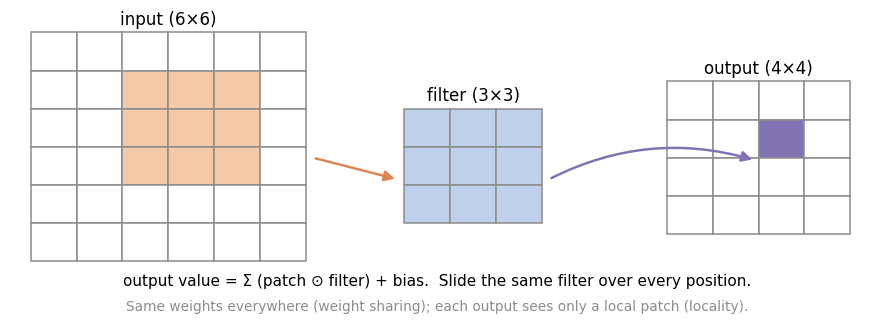

## 5.2 Convolution in 1-D: a sliding dot product
$y_i = \sum_{j=0}^{k-1} w_j\, x_{i+j} + b$. The filter `[-1, 0, 1]` responds to *changes*, so it detects steps (edges):

In [ ]:
signal = torch.tensor([0., 0., 0., 0., 1., 1., 1., 1., 0., 0., 0.])   # a rectangular pulse
kernel = torch.tensor([-1., 0., 1.])

windows = signal.unfold(0, 3, 1)                     # (9, 3): every window of length 3 (Chapter 1)
by_hand = windows @ kernel                           # dot product of each window with the filter
by_torch = F.conv1d(signal.view(1, 1, -1), kernel.view(1, 1, -1)).flatten()   # (N, C, L) layout
print("windows @ kernel:", by_hand)
print("F.conv1d:        ", by_torch)

⚠️ **Terminology.** In signal processing, convolution flips the kernel. Deep-learning "convolution" does not; strictly it is a **cross-correlation**. With learned filters this makes no difference, but it matters when you port a filter from a signals textbook.

## 5.3 Convolution in 2-D, built from patches
With $C_\text{in}$ input channels each filter spans **all** channels, and there is one filter per output channel, so the weight has shape $(C_\text{out}, C_\text{in}, k_H, k_W)$:
$$y_{o,i,j} = b_o + \sum_{c}\sum_{u,v} w_{o,c,u,v}\, x_{c,\,i+u,\,j+v}.$$
`F.unfold` cuts the input into all its $k\times k$ patches ("im2col"); each output is then a dot product of a flattened patch with a flattened filter. That is a matrix multiplication, which is why convolutions run fast on GPUs:

In [ ]:
torch.manual_seed(0)
x = torch.randn(2, 3, 6, 6)                  # (N, C_in, H, W)
w = torch.randn(4, 3, 3, 3)                  # (C_out, C_in, kH, kW): 4 filters, each 3x3 over 3 channels
b = torch.randn(4)

patches = F.unfold(x, kernel_size=3)         # (N, C_in*3*3, L): every 3x3x3 patch as a column; L = 4*4 positions
print("patches:", tuple(patches.shape))
out = torch.einsum("ok,nkl->nol", w.reshape(4, -1), patches) + b.view(1, 4, 1)   # dot product per patch & filter
out = out.reshape(2, 4, 4, 4)                # back to (N, C_out, H_out, W_out)

print("matches F.conv2d:", torch.allclose(out, F.conv2d(x, w, b), atol=1e-5))

That is all a convolutional layer computes.

## 5.4 `nn.Conv2d`: shapes and parameter counts
Output height (width alike), for kernel $k$, padding $p$, stride $s$, dilation $d$:
$$H_\text{out} = \left\lfloor \frac{H + 2p - d\,(k - 1) - 1}{s} \right\rfloor + 1.$$

| Layer on a 28×28 input | Output | Why |
| --- | --- | --- |
| `Conv2d(1, 32, 3)` | 26×26 | no padding: lose $k-1$ pixels |
| `Conv2d(1, 32, 3, padding=1)` | 28×28 | "same" size: $p = (k-1)/2$ for odd $k$ |
| `Conv2d(1, 32, 3, stride=2, padding=1)` | 14×14 | stride 2 halves the size |

**Parameters:** $C_\text{out} C_\text{in} k_H k_W + C_\text{out}$, independent of the image size.

In [ ]:
x = torch.randn(8, 1, 28, 28)
for layer in [nn.Conv2d(1, 32, 3), nn.Conv2d(1, 32, 3, padding=1), nn.Conv2d(1, 32, 3, stride=2, padding=1),
              nn.Conv2d(1, 32, 5, padding="same"), nn.Conv2d(32, 64, 3, padding=1)]:
    inp = x if layer.in_channels == 1 else torch.randn(8, 32, 28, 28)
    print(f"{str(layer):62s} -> {str(tuple(layer(inp).shape)):17s} params {count_params(layer):,}")
print(f"\nfor comparison, a Linear layer from 784 pixels to 32*28*28 outputs would have {784 * 32 * 28 * 28 + 32 * 28 * 28:,} parameters")

## 5.5 What filters detect; pooling; BatchNorm for images
Hand-made **Sobel** filters respond to vertical and horizontal edges. A trained CNN's first layer learns similar filters by itself.

In [ ]:
img = fashion_tensors("train", n=1)[0]                        # (1, 1, 28, 28): one training image
sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])
filters = torch.stack([sobel_x, sobel_x.T]).unsqueeze(1)     # (2, 1, 3, 3): vertical- and horizontal-edge filters
edges = F.conv2d(img, filters, padding=1)                    # (1, 2, 28, 28)

fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
for ax, im, title in zip(axes, [img[0, 0], edges[0, 0], edges[0, 1]], ["input", "vertical edges", "horizontal edges"]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

**Translation equivariance.** The same filter everywhere means: shift the input, and the output shifts the same way. (Circular padding makes the check exact at the borders.)

In [ ]:
conv = nn.Conv2d(1, 4, 3, padding=1, padding_mode="circular", bias=False)
shift = lambda t: torch.roll(t, shifts=(3, 5), dims=(2, 3))      # move 3 pixels down, 5 right
with torch.no_grad():
    print("conv(shift(x)) == shift(conv(x)):", torch.allclose(conv(shift(img)), shift(conv(img)), atol=1e-5))

- **Max pooling** `nn.MaxPool2d(2)` keeps the maximum of each 2×2 block, halving height and width. Together with **global average pooling** `nn.AdaptiveAvgPool2d(1)` (one average per channel, for any input size) it makes the prediction approximately **invariant** to small shifts.
- **Receptive field.** Each 3×3 layer enlarges the input region an output sees by $(k-1)\times$ (product of earlier strides); pooling makes later layers see far more.
- **`BatchNorm2d(C)`** normalises each channel over the batch **and** all positions. A convolution followed by BatchNorm is created with `bias=False` (BatchNorm's shift makes it redundant).

In [ ]:
def receptive_field(layers):
    # layers: list of (kernel_size, stride). Returns the receptive field after each layer.
    r, jump, out = 1, 1, []
    for k, s in layers:
        r += (k - 1) * jump
        jump *= s
        out.append(r)
    return out

stack = [(3, 1), (3, 1), (2, 2), (3, 1), (3, 1), (2, 2), (3, 1)]      # the CNN we build next
names = ["conv", "conv", "pool", "conv", "conv", "pool", "conv"]
for name, rf in zip(names, receptive_field(stack)):
    print(f"{name:5s} receptive field {rf:2d} x {rf:2d}")

## 5.6 A small CNN for Fashion-MNIST
The standard pattern: blocks of *convolution → BatchNorm → ReLU*, halve the resolution and double the channels, then global average pooling and a linear classifier. The class lives in the toolkit:

In [ ]:
show(conv_bn_relu); show(SmallCNN)

In [ ]:
cnn = SmallCNN()
x = torch.randn(2, 1, 28, 28)
print(f"{'input':38s} {tuple(x.shape)}")
for layer in list(cnn.features) + list(cnn.head):          # trace the shape through every stage
    x = layer(x)
    print(f"{layer.__class__.__name__ if not isinstance(layer, nn.Sequential) else 'Conv-BN-ReLU (' + str(layer[0].out_channels) + ')':38s} {tuple(x.shape)}")
print(f"\nparameters: {count_params(cnn):,}  (the MLP of Notebook 1 had 235,146)")

Train it with Chapters 2–3's tools (AdamW with weight-decay groups, OneCycle); a few seconds per epoch on a T4. The weights are saved, so later chapters can reload them with `get_trained_cnn()`:

In [ ]:
cnn, hist_cnn = train_small_cnn()
record("Ch5 SmallCNN, test accuracy", evaluate(cnn, test_loader)[1])

Typically ≈ 92–93 % test accuracy versus ≈ 88–89 % for the MLP, with **fewer** parameters (compare with your recorded numbers). Where does the gain come from?

In [ ]:
@torch.no_grad()
def per_class_accuracy(model, loader):
    model.eval()
    preds, ys = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(dim=1).cpu()); ys.append(y)
    p, t = torch.cat(preds), torch.cat(ys)
    cm = torch.bincount(t * 10 + p, minlength=100).reshape(10, 10)
    return cm.diag() / cm.sum(dim=1).clamp(min=1)

set_seed(0)
mlp_ref = build_mlp().to(device)
opt_ref = torch.optim.AdamW(mlp_ref.parameters(), lr=1e-3)
print("training the reference MLP for comparison...")
fit(mlp_ref, train_loader, val_loader, opt_ref, n_epochs(12), verbose=False)
acc_mlp, acc_cnn = per_class_accuracy(mlp_ref, test_loader), per_class_accuracy(cnn, test_loader)
for i in (acc_cnn - acc_mlp).argsort(descending=True):
    print(f"{CLASSES[i]:12s} MLP {acc_mlp[i]:.3f} -> CNN {acc_cnn[i]:.3f}  ({acc_cnn[i] - acc_mlp[i]:+.3f})")

The largest gains are usually on the upper-body garments, especially **Shirt**: collars, buttons and sleeves are local patterns. The learned first-layer filters, and the feature maps they produce:

In [ ]:
first = cnn.features[0][0].weight.detach().cpu()           # (32, 1, 3, 3)
fig, axes = plt.subplots(2, 16, figsize=(14, 2))
for i, ax in enumerate(axes.flat):
    ax.imshow(first[i, 0], cmap="RdBu"); ax.axis("off")
plt.suptitle("First-layer filters (red/blue = positive/negative weights)"); plt.show()

cnn.eval()
with torch.no_grad():
    fmap = cnn.features[:2](img.to(device))[0].cpu()        # output of the first two blocks: (32, 28, 28)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap[i], cmap="viridis"); ax.axis("off")
plt.suptitle("16 feature maps after two conv blocks (input: the image of §5.5)"); plt.show()

## 🧪 Exercises
**Exercise 5.1: output sizes.** `★☆☆ · 10 min`
Write `conv_out_size(h, k, s=1, p=0, d=1)` implementing §5.4. Then compute the size after `Conv(k=7, s=2, p=3)` → `MaxPool(k=3, s=2, p=1)` → `Conv(k=3, p=1)` → `Conv(k=3, s=2, p=1)` on a 224×224 input (pooling uses the same formula).

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# 🔎 Self-check for Exercise 5.1 (tests YOUR function)
def _test(fn):
    for h, k, s, p, d in [(28, 3, 1, 0, 1), (28, 3, 2, 1, 1), (224, 7, 2, 3, 1), (32, 3, 1, 2, 2), (15, 4, 3, 0, 1)]:
        real = nn.Conv2d(1, 1, k, stride=s, padding=p, dilation=d)(torch.zeros(1, 1, h, h)).shape[-1]
        assert fn(h, k, s, p, d) == real, f"wrong for h={h}, k={k}, s={s}, p={p}, d={d}: expected {real}"
self_check("conv_out_size", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def conv_out_size(h, k, s=1, p=0, d=1):
        return (h + 2 * p - d * (k - 1) - 1) // s + 1

    h = 224
    for k, s, p in [(7, 2, 3), (3, 2, 1), (3, 1, 1), (3, 2, 1)]:
        h = conv_out_size(h, k, s, p)
        print(h)        # 112, 56, 56, 28
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 5.2: your own `conv2d`.** `★★★ · 30 min`
Extend §5.3 into `my_conv2d(x, weight, bias, stride=1, padding=0)` for `(N, C_in, H, W)` inputs and `(C_out, C_in, k, k)` weights. `F.unfold` accepts `stride` and `padding`. It must match `F.conv2d`.

In [ ]:
# ✍️ Your attempt here.
# Hint: F.unfold(x, k, padding=padding, stride=stride) -> (N, C_in*k*k, L); einsum; add the bias; reshape to (N, C_out, H_out, W_out).

In [ ]:
# 🔎 Self-check for Exercise 5.2 (tests YOUR function)
def _test(fn):
    torch.manual_seed(0)
    for (n, c, h, w_), (o, k), s, p in [((2, 3, 9, 9), (5, 3), 1, 0), ((1, 2, 10, 7), (4, 3), 2, 1), ((3, 1, 8, 8), (2, 5), 1, 2)]:
        x, wt, b = torch.randn(n, c, h, w_), torch.randn(o, c, k, k), torch.randn(o)
        ref = F.conv2d(x, wt, b, stride=s, padding=p)
        out = fn(x, wt, b, stride=s, padding=p)
        assert out.shape == ref.shape, f"shape {tuple(out.shape)}, expected {tuple(ref.shape)}"
        assert torch.allclose(out, ref, atol=1e-4), "values differ from F.conv2d"
self_check("my_conv2d", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def my_conv2d(x, weight, bias, stride=1, padding=0):
        n, _, h, w = x.shape
        c_out, _, k, _ = weight.shape
        h_out = (h + 2 * padding - k) // stride + 1
        w_out = (w + 2 * padding - k) // stride + 1
        cols = F.unfold(x, k, padding=padding, stride=stride)                  # (N, C_in*k*k, h_out*w_out)
        out = torch.einsum("ok,nkl->nol", weight.reshape(c_out, -1), cols)     # (N, C_out, h_out*w_out)
        return (out + bias.view(1, -1, 1)).reshape(n, c_out, h_out, w_out)
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- A convolution = a dot product of every local patch with every filter; `unfold` + matrix product reproduces `F.conv2d`.
- Weight `(C_out, C_in, k, k)`; parameters independent of image size; one formula gives the output size.
- Conv → BatchNorm → ReLU blocks, pooling, global average pooling, linear head.
- Locality and weight sharing let a smaller CNN beat a larger MLP on images.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** Parameters of `nn.Conv2d(64, 128, 3)`? With `bias=False`?

<details>
<summary>Answer</summary>

128·64·3·3 + 128 = 73,856; without bias 73,728.

</details>

**2.** Output size of `Conv2d(k=3, s=2, p=1)` on 32×32?

<details>
<summary>Answer</summary>

⌊(32 + 2 − 2 − 1)/2⌋ + 1 = 16.

</details>

**3.** Why does a CNN beat an MLP on Fashion-MNIST with fewer parameters?

<details>
<summary>Answer</summary>

It builds in locality and weight sharing: a pattern detector learned once works at every position.

</details>

---
# Chapter 6. Evaluation beyond accuracy, and regression

🎯 See why accuracy misleads on imbalanced data; compute precision, recall, F1, PR and ROC curves; choose a decision threshold; compare imbalance remedies; report per-class metrics; build a regression surrogate model evaluated in physical units.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 6.1 When accuracy lies: rare defects
Synthetic quality-control data: 8 standardised sensor features per part, about **4 % defective**. Defects shift some features, but the classes overlap.

In [ ]:
def make_defect_data(n, seed, defect_rate=0.04):
    g = torch.Generator().manual_seed(seed)
    y = (torch.rand(n, generator=g) < defect_rate).long()
    X = torch.randn(n, 8, generator=g)
    shift = torch.tensor([1.2, -0.8, 0.6, 0.0, 0.0, 0.9, 0.0, -0.5])     # how a defect changes the readings
    return X + y[:, None] * shift, y

n_def = 4000 if FAST_DEV_RUN else 20000
Xd_tr, yd_tr = make_defect_data(n_def, seed=0)
Xd_va, yd_va = make_defect_data(n_def // 4, seed=1)
Xd_te, yd_te = make_defect_data(n_def // 4, seed=2)
print(f"defect rate: train {yd_tr.float().mean():.3f} | val {yd_va.float().mean():.3f} | test {yd_te.float().mean():.3f}")
print(f"accuracy of a 'model' that always says OK: {1 - yd_va.float().mean():.3f}")

A model that never finds a defect scores ≈ 96 % accuracy. Let us train a real classifier (one logit, `BCEWithLogitsLoss`):

In [ ]:
def train_defect_model(pos_weight=None, sampler=None, epochs=15, seed=0):
    set_seed(seed)
    model = nn.Sequential(nn.Linear(8, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1)).to(device)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor([pos_weight], device=device))
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3)
    loader = DataLoader(TensorDataset(Xd_tr, yd_tr.float()), batch_size=256,
                        shuffle=sampler is None, sampler=sampler)
    for _ in range(n_epochs(epochs)):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x).squeeze(1), y)
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

@torch.no_grad()
def defect_scores(model, X):
    return torch.sigmoid(model(X.to(device)).squeeze(1)).cpu()     # estimated P(defect) per part

defect_model = train_defect_model()
scores_va = defect_scores(defect_model, Xd_va)

## 6.2 The confusion matrix and its metrics
"Defect" is the **positive** class.

| | predicted defect | predicted OK |
| --- | --- | --- |
| **actual defect** | TP | FN (a **missed** defect) |
| **actual OK** | FP (a **false alarm**) | TN |

| Metric | Formula | Question |
| --- | --- | --- |
| Precision | TP / (TP + FP) | Of the flagged parts, how many are defective? |
| Recall (sensitivity) | TP / (TP + FN) | Of the defective parts, how many did we catch? |
| F1 | 2PR / (P + R) | high only if both are high |
| Specificity | TN / (TN + FP) | Of the good parts, how many did we pass? |

In [ ]:
def binary_metrics(y_true, y_pred):
    tp = ((y_pred == 1) & (y_true == 1)).sum().item()
    fp = ((y_pred == 1) & (y_true == 0)).sum().item()
    fn = ((y_pred == 0) & (y_true == 1)).sum().item()
    tn = ((y_pred == 0) & (y_true == 0)).sum().item()
    precision = tp / max(tp + fp, 1)                 # define 0/0 as 0
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {"accuracy": (tp + tn) / len(y_true), "precision": precision, "recall": recall, "f1": f1,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}

always_ok = binary_metrics(yd_va, torch.zeros_like(yd_va))
model_05 = binary_metrics(yd_va, (scores_va > 0.5).long())
for name, m in [("always OK", always_ok), ("model, threshold 0.5", model_05)]:
    print(f"{name:22s} " + " | ".join(f"{k} {v:.3f}" if isinstance(v, float) else f"{k} {v}" for k, v in m.items()))

try:                                                  # cross-check with scikit-learn, if installed
    from sklearn.metrics import precision_recall_fscore_support
    p, r, f, _ = precision_recall_fscore_support(yd_va, (scores_va > 0.5).long(), average="binary", zero_division=0)
    print(f"scikit-learn agrees: precision {p:.3f}, recall {r:.3f}, f1 {f:.3f}")
except ImportError:
    pass

The model's accuracy is barely above the trivial baseline; precision and recall show what happens: at the default threshold 0.5 it catches only part of the defects.

## 6.3 Thresholds, PR and ROC curves
The model outputs a **score**; "defect if score ≥ t" depends on a threshold **you** choose. Lower `t`: higher recall, more false alarms. Two curves summarise all thresholds:
- **precision–recall (PR)** curve, summarised by the **average precision (AP)**;
- **ROC** curve (recall vs false-positive rate FP / (FP + TN)), summarised by **ROC AUC**.

Sort the examples by score and sweep the threshold down with cumulative sums:

In [ ]:
def pr_roc(scores, y):
    order = scores.argsort(descending=True)                # threshold sweeps from high to low
    ys = y[order].float()
    tp, fp = ys.cumsum(0), (1 - ys).cumsum(0)              # counts when the top-k examples are flagged
    precision = tp / (tp + fp)
    recall = tp / ys.sum()
    fpr = fp / (1 - ys).sum()
    return precision, recall, fpr, scores[order]

prec, rec, fpr, thr = pr_roc(scores_va, yd_va)
ap = (prec * torch.diff(rec, prepend=torch.zeros(1))).sum().item()     # average precision: sum of P * (step in R)
auc = torch.trapz(torch.cat([torch.zeros(1), rec]), torch.cat([torch.zeros(1), fpr])).item()
print(f"average precision {ap:.3f} (a random model scores ≈ the defect rate, {yd_va.float().mean():.3f}) | ROC AUC {auc:.3f} (random: 0.5)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.plot(rec, prec); a1.set_xlabel("recall"); a1.set_ylabel("precision"); a1.set_title(f"PR curve (AP = {ap:.3f})")
a2.plot(fpr, rec); a2.plot([0, 1], [0, 1], "k--", lw=0.8)
a2.set_xlabel("false-positive rate"); a2.set_ylabel("recall"); a2.set_title(f"ROC curve (AUC = {auc:.3f})")
plt.tight_layout(); plt.show()

⚠️ **For rare positives, look at precision, not only ROC AUC.** The false-positive rate divides by the large number of good parts, so many false alarms can still give a small FPR and a high AUC. Report AP or, better, **precision at the recall you need**. (Ties: our sweep treats tied scores one at a time; scikit-learn groups them, which changes the numbers slightly.)

**Choosing the threshold.** Requirement: catch at least 90 % of defects. On the **validation** set, among the thresholds that reach 90 % recall, take the one with the highest precision. Then measure **once** on the test set:

In [ ]:
TARGET_RECALL = 0.90
meets = rec >= TARGET_RECALL                                # thresholds that reach the required recall
best = torch.where(meets, prec, torch.tensor(-1.0)).argmax()  # among them: the highest precision
threshold = thr[best].item()
print(f"chosen threshold on validation: {threshold:.3f} (validation precision {prec[best]:.3f}, recall {rec[best]:.3f})")

test_m = binary_metrics(yd_te, (defect_scores(defect_model, Xd_te) >= threshold).long())
print("test set at this threshold:", {k: round(v, 3) if isinstance(v, float) else v for k, v in test_m.items()})
record("Ch6 defect model, test recall at the chosen threshold", test_m["recall"])
record("Ch6 defect model, test precision at the chosen threshold", test_m["precision"])

The test recall lands near 90 % (not exactly: a threshold chosen on one sample transfers imperfectly), and the precision tells the plant how many flagged parts will turn out fine. A pair of numbers with a meaning, not "96 % accuracy".

## 6.4 Remedies for class imbalance
1. **Reweight the loss**: `BCEWithLogitsLoss(pos_weight=n_neg / n_pos)` counts each defect about 23 times here, so that all defects **together** weigh as much as all good parts.
2. **Resample**: `WeightedRandomSampler` draws defects more often, so batches are roughly balanced.
3. **Move the threshold** (§6.3), leaving training unchanged.

AP does not depend on the threshold, so it compares the **ranking** quality itself:

In [ ]:
from torch.utils.data import WeightedRandomSampler

def average_precision_of(model, X, y):
    p, r, _, _ = pr_roc(defect_scores(model, X), y)
    return (p * torch.diff(r, prepend=torch.zeros(1))).sum().item()

n_pos, n_neg = yd_tr.sum().item(), (1 - yd_tr).sum().item()
class_weight = torch.where(yd_tr == 1, 1.0 / n_pos, 1.0 / n_neg)          # each class gets half the draws
sampler = WeightedRandomSampler(class_weight, num_samples=len(yd_tr), replacement=True)
variants = {"plain": train_defect_model(),
            "pos_weight": train_defect_model(pos_weight=n_neg / n_pos),
            "balanced sampler": train_defect_model(sampler=sampler)}
for name, m in variants.items():
    s = defect_scores(m, Xd_va)
    f05 = binary_metrics(yd_va, (s > 0.5).long())
    print(f"{name:17s} AP {average_precision_of(m, Xd_va, yd_va):.3f} | at threshold 0.5: "
          f"precision {f05['precision']:.3f}, recall {f05['recall']:.3f} | mean score {s.mean():.3f}")

Typically all three reach a similar AP: reweighting and resampling mostly **shift the scores up** (see the mean score), raising recall and lowering precision at the fixed threshold 0.5, while the ranking barely changes. Consequences:
- They help when you must use a fixed threshold, or when the minority is so rare that training ignores it.
- The scores of a reweighted model are **no longer calibrated probabilities** (they overestimate the defect rate).
- Threshold tuning on validation is cheap, keeps the scores calibrated, and is often enough.

## 6.5 Multi-class: per-class, macro and micro averages
Compute precision, recall and F1 **per class** (each class in turn is "positive"). **Macro** average = plain mean over classes (rare classes count equally). **Micro** average pools all TP/FP/FN first; for single-label classification micro-F1 equals accuracy. The CNN of Chapter 5:

In [ ]:
cnn = get_trained_cnn()
preds, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds.append(cnn(x.to(device)).argmax(dim=1).cpu()); ys.append(y.cpu())
pred_t, true_t = torch.cat(preds), torch.cat(ys)
cm = torch.bincount(true_t * 10 + pred_t, minlength=100).reshape(10, 10).float()   # rows: true, columns: predicted
tp = cm.diag()
precision_c = tp / cm.sum(dim=0).clamp(min=1)
recall_c = tp / cm.sum(dim=1).clamp(min=1)
f1_c = 2 * precision_c * recall_c / (precision_c + recall_c).clamp(min=1e-12)
for i in f1_c.argsort():
    print(f"{CLASSES[i]:12s} precision {precision_c[i]:.3f} | recall {recall_c[i]:.3f} | F1 {f1_c[i]:.3f}")
print(f"\nmacro-F1 {f1_c.mean():.4f} | micro-F1 = accuracy {(tp.sum() / cm.sum()):.4f}")

`torchmetrics` and scikit-learn's `classification_report` compute these for you; knowing the definitions lets you check them and pick the right average.

## 6.6 Regression: a surrogate model for a vibrating system
Engineers replace expensive simulations with fast neural **surrogates**. Our "simulation" is the steady-state amplitude of a forced spring–mass–damper,
$$A = \frac{F_0}{\sqrt{(k - m\omega^2)^2 + (c\omega)^2}},$$
with $m$ 0.5–5 kg, $k$ 100–5000 N/m, $c$ 0.5–50 N·s/m, $F_0$ 1–100 N, $\omega$ 1–100 rad/s. The inputs span decades in different units, and the amplitude spans several orders of magnitude, with sharp peaks at resonance ($\omega^2 \approx k/m$).

In [ ]:
def make_spring_data(n, seed):
    g = torch.Generator().manual_seed(seed)
    lo = torch.tensor([0.5, 100.0, 0.5, 1.0, 1.0])            # m, k, c, F0, omega
    hi = torch.tensor([5.0, 5000.0, 50.0, 100.0, 100.0])
    u = torch.rand(n, 5, generator=g)
    X = torch.exp(lo.log() + u * (hi.log() - lo.log()))       # log-uniform: every decade equally represented
    m, k, c, F0, w = X.unbind(dim=1)
    A = F0 / torch.sqrt((k - m * w ** 2) ** 2 + (c * w) ** 2)
    return X, A

n_spr = 4000 if FAST_DEV_RUN else 20000
Xs_tr, As_tr = make_spring_data(n_spr, seed=0)
Xs_va, As_va = make_spring_data(4000, seed=1)
Xs_te, As_te = make_spring_data(4000, seed=2)
print(f"amplitude range: {As_tr.min():.2e} to {As_tr.max():.2e} m")

Three decisions make or break such a model:
1. **Input transform:** positive inputs spanning decades → $\log x$, then standardise with **training** statistics.
2. **Target transform:** train on $\log A$, standardised. An MSE on $\log A$ penalises **relative** errors (10 % off counts the same for tiny and huge amplitudes), and $\exp$ makes predictions positive.
3. **Evaluate in physical units:** the relative error $|\hat A - A| / A$.

The transforms are **part of the model**, so `train_surrogate` fits them on the data it is given and returns them together with the network:

In [ ]:
class Standardizer:
    # Fitted on training data only; applies the same frozen statistics everywhere (Notebook 1, §6.2).
    def __init__(self, z):
        self.mean, self.std = z.mean(dim=0), z.std(dim=0)
    def __call__(self, z):
        return (z - self.mean) / self.std
    def inverse(self, z):
        return z * self.std + self.mean

class Surrogate:
    # A trained network TOGETHER with the transforms it was trained with.
    def __init__(self, net, x_scaler, y_scaler, log_target):
        self.net, self.x_scaler, self.y_scaler, self.log_target = net, x_scaler, y_scaler, log_target

    @torch.no_grad()
    def predict(self, X):                                    # physical inputs -> amplitude in metres
        z = self.y_scaler.inverse(self.net(self.x_scaler(X.log()).to(device)).squeeze(1).cpu())
        return z.exp() if self.log_target else z

def train_surrogate(X, A, log_target=True, epochs=60, seed=0, width=128, lr=3e-3):
    x_scaler = Standardizer(X.log())                         # fitted on THIS training data only
    target = A.log() if log_target else A
    y_scaler = Standardizer(target)
    set_seed(seed)
    loader = DataLoader(TensorDataset(x_scaler(X.log()), y_scaler(target)[:, None]),
                        batch_size=256, shuffle=True, drop_last=True)
    net = nn.Sequential(nn.Linear(5, width), nn.SiLU(), nn.Linear(width, width), nn.SiLU(),
                        nn.Linear(width, width), nn.SiLU(), nn.Linear(width, 1)).to(device)
    E = n_epochs(epochs)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)   # OneCycleLR sets the actual lr
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=E * len(loader))
    for _ in range(E):
        net.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = F.mse_loss(net(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return Surrogate(net.eval(), x_scaler, y_scaler, log_target)

def rel_errors(surrogate, X, A):
    return (surrogate.predict(X) - A).abs() / A

surrogate = train_surrogate(Xs_tr, As_tr)
rel_err = rel_errors(surrogate, Xs_va, As_va)
print(f"validation relative error: median {rel_err.median():.4f} | 90th percentile {rel_err.quantile(0.9):.4f} | max {rel_err.max():.3f}")
record("Ch6 surrogate, median relative error (val)", rel_err.median().item())

For reference, a CPU run gave a median relative error of about 0.5 % and a 90th percentile of about 2 %. A median hides the worst cases: look at the tail too, and at **where** the errors occur:

In [ ]:
A_hat = surrogate.predict(Xs_va)
m, k, c, F0, w = Xs_va.unbind(dim=1)
ratio = w / torch.sqrt(k / m)                                   # forcing frequency / natural frequency

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.loglog(As_va, A_hat, ".", ms=2, alpha=0.5); a1.loglog([1e-5, 10], [1e-5, 10], "k--", lw=0.8)
a1.set_xlabel("true amplitude (m)"); a1.set_ylabel("predicted amplitude (m)"); a1.set_title("Parity plot")
a2.semilogx(ratio, (A_hat - As_va).abs() / As_va, ".", ms=2, alpha=0.5)
a2.axvline(1.0, color="tab:red", ls="--", lw=0.8, label="resonance")
a2.set_xlabel("ω / ω_n"); a2.set_ylabel("relative error"); a2.set_yscale("log"); a2.legend(); a2.set_title("Where are the errors?")
plt.tight_layout(); plt.show()

The parity plot hugs the diagonal across several decades; the largest errors cluster around **resonance** ($\omega/\omega_n \approx 1$), where the amplitude changes fastest. Surrogates are least reliable exactly where the physics is sharpest: add training samples there, report the uncertainty, and **never** use a surrogate outside the input ranges it was trained on.

## 6.7 ★ Choosing hyper-parameters honestly
**Random search.** Sample settings at random (learning rates log-uniformly), train each briefly, keep the best by **validation** score. For the same budget it usually beats a grid, because it tries more distinct values of the settings that matter.

In [ ]:
gen = torch.Generator().manual_seed(0)
trials = []
for t in range(2 if FAST_DEV_RUN else 6):
    lr = 10 ** torch.empty(1).uniform_(-3.5, -2, generator=gen).item()          # 3e-4 ... 1e-2, log-uniform
    width = [32, 64, 128][torch.randint(0, 3, (1,), generator=gen).item()]
    m = train_surrogate(Xs_tr[:5000], As_tr[:5000], epochs=15, lr=lr, width=width)   # short, cheap trials
    med = rel_errors(m, Xs_va, As_va).median().item()
    trials.append((med, lr, width))
    print(f"trial {t}: lr {lr:.1e}, width {width:3d} -> validation median relative error {med:.4f}")
best = min(trials)
print(f"best: lr {best[1]:.1e}, width {best[2]} ({best[0]:.4f})")

Short trials on a quarter of the data are far less accurate than the full model; their job is to **rank** settings cheaply. Short-budget rankings can differ from full-budget ones, so confirm the winner with a full run.

**k-fold cross-validation.** With small data a single validation split is noisy. Split the training data into k folds, train k times (each fold validates once) and report mean ± std. Because `train_surrogate` fits its scalers on each fold's training part only, nothing leaks.

In [ ]:
def kfold_indices(n, k, seed=0):
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed))
    return perm.chunk(k)                                     # k nearly equal folds

n_small, K = 600, (2 if FAST_DEV_RUN else 5)                 # pretend only 600 simulations are affordable
folds = kfold_indices(n_small, K)
fold_errors = []
for i in range(K):
    val_idx = folds[i]
    tr_idx = torch.cat([f for j, f in enumerate(folds) if j != i])
    m = train_surrogate(Xs_tr[tr_idx], As_tr[tr_idx], epochs=40)
    fold_errors.append(rel_errors(m, Xs_tr[val_idx], As_tr[val_idx]).median().item())
    print(f"fold {i}: median relative error {fold_errors[-1]:.4f}")
fe = torch.tensor(fold_errors)
print(f"{K}-fold estimate: {fe.mean():.4f} ± {fe.std():.4f}")

With 600 simulations the surrogate is far less accurate than with 20,000 (a CPU run gave a median error of about 45 % versus 0.5 %), and the spread across folds tells you how far that estimate itself can be trusted.

## 6.8 ★ Are the probabilities trustworthy? Calibration
A classifier is **calibrated** if, of all predictions made with 80 % confidence, about 80 % are correct. Networks trained with cross-entropy are often **over-confident**. The **expected calibration error (ECE)** bins predictions by confidence and averages |confidence − accuracy| over the bins.

**Temperature scaling** divides all logits by one scalar $T$ fitted on the **validation** set (minimising the NLL). Dividing by $T$ keeps the largest logit largest, so **accuracy is unchanged**. Check on the test set whether it helps *your* model:

In [ ]:
@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    out, ys = [], []
    for x, y in loader:
        out.append(model(x.to(device)).float().cpu()); ys.append(y)
    return torch.cat(out), torch.cat(ys)

def ece(logits, y, n_bins=15):
    conf, pred = torch.softmax(logits, dim=1).max(dim=1)
    correct = (pred == y).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.float().mean() * (conf[m].mean() - correct[m].mean()).abs()
    return float(total)

cnn = get_trained_cnn()                                       # the Chapter 5 network
val_logits, val_y = collect_logits(cnn, val_loader)
test_logits, test_y = collect_logits(cnn, test_loader)

log_t = torch.zeros(1, requires_grad=True)                 # optimise log T so that T stays positive
opt_t = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100, line_search_fn="strong_wolfe")
def closure():
    opt_t.zero_grad()
    loss = F.cross_entropy(val_logits / log_t.exp(), val_y)
    loss.backward()
    return loss
opt_t.step(closure)
temperature = log_t.exp().item()

print(f"fitted temperature T = {temperature:.3f}")
print(f"test ECE before: {ece(test_logits, test_y):.4f} | after: {ece(test_logits / temperature, test_y):.4f}")
record("Ch6 SmallCNN test ECE after temperature scaling", ece(test_logits / temperature, test_y))
print(f"test NLL before: {F.cross_entropy(test_logits, test_y):.4f} | after: {F.cross_entropy(test_logits / temperature, test_y):.4f}")

## 🧪 Exercises
**Exercise 6.1: average precision.** `★★☆ · 15 min`
Write `average_precision(scores, y)`: the mean, over all positives, of the precision at the rank where each positive is found.

In [ ]:
# ✍️ Your attempt here.
# Hint: sort by score; precision@k = (positives among the first k) / k; average it over the positions of the positives.

In [ ]:
# 🔎 Self-check for Exercise 6.1 (tests YOUR function)
def _test(fn):
    s = torch.tensor([0.9, 0.8, 0.7, 0.6, 0.5, 0.4])
    y = torch.tensor([1, 0, 1, 0, 0, 1])
    expected = (1 / 1 + 2 / 3 + 3 / 6) / 3
    assert abs(fn(s, y) - expected) < 1e-6, f"got {fn(s, y)}, expected {expected:.6f}"
    g = torch.Generator().manual_seed(0)
    s2, y2 = torch.rand(200, generator=g), (torch.rand(200, generator=g) < 0.2).long()
    p, r, _, _ = pr_roc(s2, y2)
    ref = (p * torch.diff(r, prepend=torch.zeros(1))).sum().item()
    assert abs(fn(s2, y2) - ref) < 1e-5, "does not match the §6.3 computation"
self_check("average_precision", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def average_precision(scores, y):
        ys = y[scores.argsort(descending=True)].float()
        hits = ys.cumsum(0)                                   # positives among the first k
        precision_at_k = hits / torch.arange(1, len(ys) + 1)
        return float((precision_at_k * ys).sum() / ys.sum())  # average over the positions of the positives

    print(average_precision(torch.tensor([0.9, 0.8, 0.7]), torch.tensor([1, 0, 1])))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 6.2: skip the target transform.** `★★☆ · 15 min`
Train `train_surrogate(Xs_tr, As_tr, log_target=False)` (standardise $A$ itself) and compute the same relative-error statistics on the validation set. How many predicted amplitudes are **negative**? Explain.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    raw = train_surrogate(Xs_tr, As_tr, log_target=False)
    A_raw = raw.predict(Xs_va)
    rel = (A_raw - As_va).abs() / As_va
    print(f"raw target: median {rel.median():.4f} | 90th percentile {rel.quantile(0.9):.4f} | "
          f"non-positive predictions {(A_raw <= 0).float().mean():.1%}")
    # On the raw scale the MSE is dominated by the few large amplitudes near resonance. An error of 1e-4 m is
    # invisible to it, although it is a 100 % error for a part that only moves 1e-4 m. Nothing keeps the
    # predictions positive either. The log target fixes both.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Imbalanced data: report precision, recall, F1 and AP (or precision at the required recall), not accuracy alone.
- The threshold is a design decision: choose it on validation from the costs of misses and false alarms; test once.
- Reweighting and resampling mainly shift scores; threshold tuning is often enough.
- Regression: transform inputs and targets to sensible scales, keep the transforms with the model, evaluate in physical units, including the error tail.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** A fault detector has 99.5 % accuracy on data with 0.5 % faults. What do you ask?

<details>
<summary>Answer</summary>

Its recall and precision on the fault class (or AP). Never reporting a fault also scores 99.5 %.

</details>

**2.** Why choose the threshold on validation rather than test data?

<details>
<summary>Answer</summary>

It is a modelling decision; using the test set for it makes the test result optimistic.

</details>

**3.** Why is an MSE on log A a good loss for a quantity spanning orders of magnitude?

<details>
<summary>Answer</summary>

A difference of logs is a ratio, so relative errors count equally for small and large values; and exp guarantees positive predictions.

</details>

---
# Chapter 7. Debugging training

🎯 Follow a protocol that finds most training bugs quickly; hunt `NaN`s; map symptoms to causes.

Training bugs rarely crash: the loss goes down a little and the model is just worse than it should be. Be systematic; staring at code is slow.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 7.1 The protocol
Go in order; each step is cheap and rules out a whole class of bugs.

| Step | Do | Catches |
| --- | --- | --- |
| 1 | **Smoke test** the whole pipeline with `FAST_DEV_RUN = True` | crashes in rarely run code (evaluation, saving) |
| 2 | **Look at a batch**: images, labels, value ranges, shapes, dtypes | wrong labels, broken normalisation, misaligned data |
| 3 | **Initial loss** ≈ ln C | bad initialisation, wrong loss setup |
| 4 | **Overfit one batch** to near-zero loss | bugs in model, loss or loop (Notebook 1, §7.9) |
| 5 | **Activations and gradient norms per layer** (Chapter 1's hooks) | vanishing/exploding signals, dead units, disconnected layers |
| 6 | **Scale up**; watch the curves, the learning rate and the gradient norm | overfitting, learning-rate problems, instabilities |

## 7.2 Hunting NaNs
One `NaN` spreads quickly: a `NaN` loss makes every gradient `NaN`, and one optimizer step then corrupts the weights. Common causes:

| Cause | Example |
| --- | --- |
| learning rate too high | the loss rises, becomes `inf`, then `nan` |
| `log(0)` or division by ~0 in hand-written code | `torch.log(probs)` with a probability that underflowed to 0 |
| a derivative that is infinite at 0 | `x.sqrt()` at 0, e.g. in a hand-written distance |
| bad data | a `NaN` in the input file |

`torch.autograd.detect_anomaly()` checks every backward operation and reports the **first** one that produced a `NaN`, with a traceback to the forward line. It is slow: use it only while debugging.

In [ ]:
import warnings

def pairwise_dist(a, b):
    return ((a - b) ** 2).sum(dim=1).sqrt()                # hand-written Euclidean distance

a = torch.randn(4, 3, requires_grad=True)
b = a.detach().clone() + 1.0                               # every example at distance > 0 ...
b[0] = a[0].detach()                                       # ... except example 0: distance exactly 0
loss = pairwise_dist(a, b).mean()
loss.backward()
print("loss is finite:", torch.isfinite(loss).item(), "| but a.grad has NaN:", torch.isnan(a.grad).any().item())

a.grad = None
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    with torch.autograd.detect_anomaly():
        try:
            pairwise_dist(a, b).mean().backward()
        except RuntimeError as e:
            print("detect_anomaly:", str(e)[:120])

The loss is finite, yet the gradient has a `NaN`. Backwards: $\frac{d}{dx}\sqrt{x} = \frac{1}{2\sqrt{x}}$ is **infinite** at 0, so `SqrtBackward0` outputs `inf`; the square's backward then multiplies by $2(a-b) = 0$, and $\infty \cdot 0 = \text{NaN}$. So anomaly detection names `PowBackward0`, the first operation whose output is `NaN`; the root cause is often the operation just before it in the forward pass (the `sqrt`). Fix: `(... + 1e-12).sqrt()`, or `torch.cdist` / `F.pairwise_distance`. In loops, a cheap guard is `if not torch.isfinite(loss): ...` with a clear message.

## 7.3 A field guide to symptoms
| Symptom | Likely causes | First check |
| --- | --- | --- |
| loss exactly flat from the start | `step()` missing or before `backward()`; parameters not registered; lr = 0; everything frozen | `count_params(model)`; do weights change after one step? |
| initial loss far from ln C | wrong output size; unnormalised inputs; bad init; softmax applied twice | logits statistics on one batch |
| accuracy at chance, loss slowly falls | labels misaligned with inputs | plot images with their labels |
| cannot overfit one batch | model bug; loss contract violated; too much regularisation | overfit without dropout and weight decay |
| loss spikes, then `nan` | learning rate too high; no warm-up | lower the lr, add clipping and warm-up; log the gradient norm |
| training loss falls, validation flat from the start | train and validation preprocessed differently; wrong validation labels | evaluate on a slice of the **training** set with the validation pipeline |
| validation result changes between identical evaluations | `model.eval()` missing | evaluate twice and compare |
| memory grows every step | losses accumulated without `.item()`; lists of GPU tensors | what do you append to lists? |

## 🧪 Exercise 7.1: debug a training script  `★★★ · 30 min`
`buggy_training` trains an MLP on 4,096 clean Fashion-MNIST images. It runs without errors, yet validation accuracy is terrible. It has **four** independent bugs (one each in the data, the model, the loop and the evaluation). Use the protocol and the field guide, then write `fixed_training()`; it should reach roughly 80–85 % validation accuracy.

In [ ]:
small_ds = TensorDataset(*fashion_tensors("train", n=4096))
small_val = TensorDataset(*fashion_tensors("val", n=2000))

In [ ]:
def buggy_training(epochs=5, seed=0):
    set_seed(seed)
    X = small_ds.tensors[0]                                   # (4096, 1, 28, 28), normalised
    Y = small_ds.tensors[1]
    perm = torch.randperm(len(X))
    train_ds = TensorDataset(X[perm], Y)                      # shuffle the training set
    loader = DataLoader(train_ds, batch_size=128, shuffle=True)

    model = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.5),
                          nn.Linear(256, 10), nn.Softmax(dim=1)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
        with torch.no_grad():                                 # validation
            logits = model(small_val.tensors[0].to(device))
            acc = (logits.argmax(dim=1).cpu() == small_val.tensors[1]).float().mean().item()
        print(f"epoch {epoch + 1}: val acc {acc:.3f}")

buggy_training()

In [ ]:
# ✍️ Your attempt here.
# Hint: bugs hide in the data, the model, the loop and the evaluation: one in each.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def fixed_training(epochs=5, seed=0):
        set_seed(seed)
        X, Y = small_ds.tensors
        # Bug 1: X[perm] with an unshuffled Y destroys the pairing of images and labels -> chance accuracy.
        #        The DataLoader already shuffles (keeping pairs intact), so no manual shuffle is needed.
        loader = DataLoader(TensorDataset(X, Y), batch_size=128, shuffle=True)

        # Bug 2: nn.Softmax before CrossEntropyLoss (double softmax, Notebook 1 §5.3): the model must output logits.
        model = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.5),
                              nn.Linear(256, 10)).to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
        loss_fn = nn.CrossEntropyLoss()

        for epoch in range(epochs):
            model.train()
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                loss = loss_fn(model(x), y)
                opt.zero_grad()                  # Bug 3: without it, gradients accumulate over all past steps
                loss.backward()
                opt.step()
            model.eval()                         # Bug 4: without eval(), Dropout(0.5) is active during validation
            with torch.no_grad():
                logits = model(small_val.tensors[0].to(device))
                acc = (logits.argmax(dim=1).cpu() == small_val.tensors[1]).float().mean().item()
            print(f"epoch {epoch + 1}: val acc {acc:.3f}")

    fixed_training()
    # How the protocol finds them: plotting a batch with its labels (step 2) reveals bug 1; the
    # initial-loss and overfit-one-batch checks (steps 3-4) expose bug 2 (the loss cannot go below
    # about 1.46); printing whether the weights change sensibly, or the gradient norm growing every
    # step, reveals bug 3; evaluating twice and getting different numbers reveals bug 4.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Follow the protocol: smoke test, look at data, initial loss, overfit one batch, per-layer statistics, then scale up.
- `detect_anomaly()` names the first backward operation that produced a `NaN`; look just before it.
- Most silent bugs live at interfaces: data ↔ labels, model ↔ loss, train ↔ eval mode.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** The loss is finite, but after one step all weights are NaN. Where do you look?

<details>
<summary>Answer</summary>

At the backward pass: something produced inf/NaN gradients (sqrt or log at 0, division by ~0). Run one step under `detect_anomaly()`.

</details>

**2.** Training loss falls, validation accuracy stays at chance. Three possible causes?

<details>
<summary>Answer</summary>

Validation labels misaligned with inputs; different preprocessing for validation; evaluation bugs (wrong labels compared, `eval()` forgotten with heavy dropout).

</details>

---
# Chapter 8. Using a trained model

🎯 Run inference without the classic mistakes; package preprocessing with the model; save what is needed to use it later; export a self-contained graph.

*Fresh session?* Run the two Chapter 0 cells first; nothing else is needed.

## 8.1 The inference checklist
| ✔ | Item | Why |
| --- | --- | --- |
| 1 | `model.eval()` | Dropout off, BatchNorm uses running statistics |
| 2 | `torch.inference_mode()` (or `no_grad`) | no graph: faster, less memory |
| 3 | **identical preprocessing** to training | same scaling, normalisation statistics, size, channel order |
| 4 | a batch dimension | models expect `(N, …)`: `x.unsqueeze(0)` |
| 5 | the right device and dtype | inputs on the model's device, `float32` |
| 6 | output post-processing | softmax for probabilities; class index → name |
| 7 | weights + config + class names + preprocessing stored **together** | the model can be rebuilt and used correctly |

## 8.2 Put the preprocessing inside the model
The most common deployment bug is preprocessing that differs between training and use. Make it **part of the model**: the normalisation constants become **buffers** (saved with the weights, moved by `.to()`, never trained), and the model takes raw images.

In [ ]:
class FashionClassifier(nn.Module):
    # Deployable model: takes raw uint8 images (N, 1, 28, 28) with values 0..255, returns class probabilities.
    def __init__(self, net, mean, std, class_names):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32))
        self.class_names = list(class_names)            # plain attribute: NOT in state_dict or exports (see 8.3)

    def forward(self, images):
        x = (images.float() / 255.0 - self.mean) / self.std     # exactly the training preprocessing
        return torch.softmax(self.net(x), dim=1)

cnn = get_trained_cnn()                                        # the network trained in Chapter 5
fm = fashion_mnist()
deploy = FashionClassifier(copy.deepcopy(cnn).cpu(), fm["mean"], fm["std"], CLASSES).eval()

test_raw = fm["raw_test"]
raw_batch = test_raw.data[:8].unsqueeze(1)                     # uint8, (8, 1, 28, 28): straight from the file
with torch.inference_mode():
    probs = deploy(raw_batch)
    reference = torch.softmax(cnn.cpu().eval()(fashion_tensors("test", n=8)[0]), dim=1)   # the training pipeline
cnn.to(device)
print("same output as the training pipeline:", torch.allclose(probs, reference, atol=1e-5))
print("predictions:", [deploy.class_names[i] for i in probs.argmax(dim=1)])

## 8.3 Saving everything needed, and `torch.export`
Loading a `state_dict` needs the model's **Python class**. `torch.export.export(model, example_inputs)` instead captures the computation itself as an **`ExportedProgram`** (operations + weights), saved as a `.pt2` file that loads without your source code. It is PyTorch's current deployment path; the older **TorchScript** (`torch.jit`) is deprecated.

- By default the graph is specialised to the example's shapes: declare the batch dimension **dynamic** with `torch.export.Dim`.
- ⚠️ `class_names` is a plain attribute, so it is in neither the `state_dict` nor the graph. Store such metadata explicitly: next to the `state_dict`, and as `extra_files` inside the `.pt2`.

In [ ]:
example = test_raw.data[:4].unsqueeze(1)                       # uint8 (4, 1, 28, 28)
batch = torch.export.Dim("batch", min=1, max=1024)
exported = torch.export.export(deploy, (example,), dynamic_shapes={"images": {0: batch}})
import json
meta = {"classes": CLASSES, "input": "uint8 (N, 1, 28, 28), values 0-255", "output": "class probabilities (N, 10)"}
torch.export.save(exported, DATA_DIR / "fashion_classifier.pt2", extra_files={"meta.json": json.dumps(meta)})
torch.save({"state_dict": deploy.state_dict(), "meta": meta}, DATA_DIR / "fashion_classifier_weights.pt")

extra = {"meta.json": ""}                                     # names of the extra files to read back
program = torch.export.load(DATA_DIR / "fashion_classifier.pt2", extra_files=extra)
loaded = program.module()                                     # no FashionClassifier class needed
loaded_classes = json.loads(extra["meta.json"])["classes"]
print("class names read back from the .pt2 file:", loaded_classes[:3], "...")
for n in (1, 7):
    xi = test_raw.data[:n].unsqueeze(1)
    with torch.inference_mode():
        print(f"batch {n}: matches the eager model:", torch.allclose(loaded(xi), deploy(xi), atol=1e-6),
              "| first prediction:", loaded_classes[loaded(xi).argmax(dim=1)[0]])
print("\nfirst lines of the exported graph:")
print("\n".join(str(exported.graph_module.code).strip().splitlines()[:6]))

The graph shows the BatchNorm statistics and our `mean`/`std` buffers captured like the weights. Export is strict: data-dependent Python control flow must be rewritten (e.g. with `torch.cond`); its error messages name the offending line.

## 🧪 Exercises
**Exercise 8.1: a reusable deployment test.** `★★☆ · 15 min`
Write `is_batch_independent(model, x, atol=1e-5)`: in the model's **current** mode and without gradients, do the predictions for `x[:2]` alone equal the first two rows of the predictions for the whole `x`? It should be `True` for `cnn.eval()` and `False` for `cnn.train()` (BatchNorm uses batch statistics). Do not change the model's mode.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# 🔎 Self-check for Exercise 8.1 (tests YOUR function)
def _test(fn):
    m = SmallCNN(p_drop=0.0).to(device)
    x = torch.randn(16, 1, 28, 28, device=device) * 3
    m.eval()
    assert fn(m, x) is True or fn(m, x) == True, "should be True in eval mode"
    m.train()
    assert not fn(m, x), "should be False in train mode (BatchNorm uses batch statistics)"
    assert m.training, "the function must not change the model's mode"
self_check("is_batch_independent", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def is_batch_independent(model, x, atol=1e-5):
        with torch.no_grad():
            full = model(x)
            part = model(x[:2])
        return bool(torch.allclose(full[:2], part, atol=atol))

    print("eval: ", is_batch_independent(cnn.eval(), next(iter(val_loader))[0].to(device)))
    print("train:", is_batch_independent(cnn.train(), next(iter(val_loader))[0].to(device)))
    cnn.eval()
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 8.2: what static shapes cost.** `★☆☆ · 10 min`
Export `deploy` again **without** `dynamic_shapes` (batch-of-4 example). Call it with a batch of 4, then 7. What happens, and why?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    static = torch.export.export(deploy, (example,)).module()
    print("batch 4:", static(test_raw.data[:4].unsqueeze(1)).shape)
    try:
        static(test_raw.data[:7].unsqueeze(1))
    except Exception as e:
        print("batch 7:", type(e).__name__, str(e)[:150])
    # Without dynamic_shapes the batch size 4 is baked into the graph as a constant, and the exported
    # program checks its inputs against those shapes. Declare every dimension that can vary.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Inference = `eval()` + `inference_mode()` + identical preprocessing + a batch dimension.
- Put preprocessing inside the model as buffers; store class names and config with the weights.
- `torch.export` gives a code-free `.pt2` graph; declare dynamic dimensions.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** Why is normalisation as buffers better than documenting the statistics?

<details>
<summary>Answer</summary>

The statistics travel with the weights in every saved or exported file, so callers cannot apply different preprocessing by mistake.

</details>

**2.** An exported model works for batch 4 but fails for batch 7. What was forgotten?

<details>
<summary>Answer</summary>

Declaring the batch dimension dynamic (`dynamic_shapes` with `torch.export.Dim`).

</details>

---
# Summary: a complete training script
```python
# ---- configuration and reproducibility ----
cfg = dict(lr=1e-3, weight_decay=0.05, epochs=20, batch_size=128, seed=0); set_seed(cfg["seed"])

# ---- data: split first, statistics from the training split, augmentation only for training ----
train_loader = DataLoader(train_ds, cfg["batch_size"], shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, 1024)

# ---- model: ReLU + He init or BatchNorm; outputs logits ----
model = build_model(cfg).to(device)
optimizer = torch.optim.AdamW(param_groups_weight_decay(model, cfg["weight_decay"]), lr=cfg["lr"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, cfg["lr"], total_steps=cfg["epochs"] * len(train_loader))
early_stopping = EarlyStopping(patience=5)

for epoch in range(cfg["epochs"]):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()                               # per batch, after optimizer.step()
    val_loss, val_acc = evaluate(model, val_loader)    # eval() + no_grad inside
    save_checkpoint("last.pt", model, optimizer, scheduler, epoch)   # resumable
    if early_stopping.step(val_loss, model):
        break
early_stopping.restore(model)

# ---- once: test, report precision/recall where it matters, save weights + config + metadata ----
```

## Your results
Values quoted in the text are typical, not guaranteed; your run is the ground truth.

In [ ]:
for name, value in RESULTS.items():
    print(f"{name:62s} {value:.4f}")

## Where to go next
- The official tutorials and documentation: [pytorch.org/tutorials](https://pytorch.org/tutorials), [pytorch.org/docs](https://pytorch.org/docs).
- The ★ appendices below: tensor internals, `einsum`, weight averaging, higher-order autograd and a PINN, performance, export to ONNX.
- Later in the course: other architectures. Everything here (the training loop, initialisation, optimizers, schedules, regularisation, evaluation, debugging) carries over unchanged.

---
# ★ Optional appendices
Independent of each other; each needs only the two Chapter 0 cells (Appendix F also needs Chapter 8).

| | Topic | Time |
| --- | --- | --- |
| A | Tensor internals: storage, strides, views | 40 min |
| B | `einsum`: index notation as code | 25 min |
| C | Weight averaging: EMA and SWA | 30 min |
| D | Higher-order autograd and a physics-informed network | 35 min |
| E | Performance: data pipelines, mixed precision, `torch.compile` | 35 min |
| F | ONNX, latency, and a small project with tests | 30 min |
| G | An error-message decoder | reference |

---
# Appendix A. Tensor internals: storage, strides, views

A tensor's numbers live in a flat **storage**. The tensor is a description of how to read it: `storage_offset()`, `shape` and `stride()` (how many storage positions to jump per step along each dimension). The address of element `[i, j]` is `offset + i·stride[0] + j·stride[1]`.

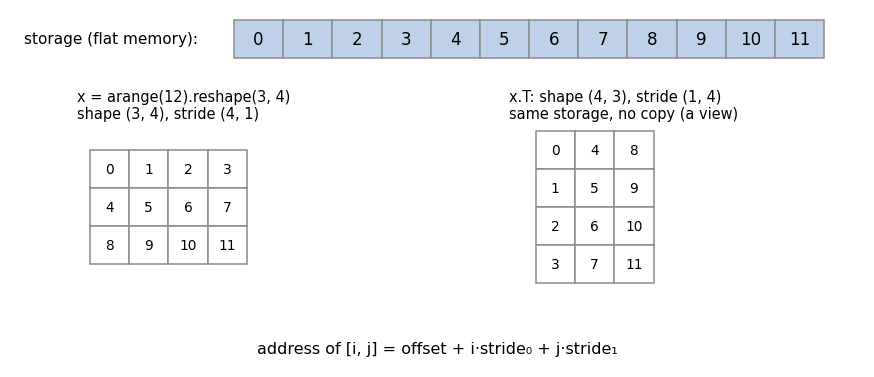

In [ ]:
x = torch.arange(12).reshape(3, 4)
print(x)
print("shape:", tuple(x.shape), "| stride:", x.stride(), "| offset:", x.storage_offset())

def address(t, idx):
    # Storage position of element t[idx], computed from offset and strides.
    return t.storage_offset() + sum(i * s for i, s in zip(idx, t.stride()))

print("x[2, 1] =", x[2, 1].item(), "lives at storage position", address(x, (2, 1)), "= 0 + 2*4 + 1*1")

For a contiguous tensor the last stride is 1 and each earlier stride is the product of all later sizes: `(2, 3, 4)` has strides `(12, 4, 1)`.

## A.1 Views share memory
Slicing, `transpose`, `permute`, `expand`, `squeeze`/`unsqueeze` and (when possible) `view` only change the description. They return a **view** of the same storage: free to create, and writes through a view change the original.

In [ ]:
x = torch.arange(12).reshape(3, 4)

def describe(name, t):
    print(f"{name:10s} shape={str(tuple(t.shape)):9s} stride={str(t.stride()):8s} offset={t.storage_offset()}  "
          f"shares memory with x: {t.untyped_storage().data_ptr() == x.untyped_storage().data_ptr()}")

describe("x", x)
describe("x[1]", x[1])              # row 1: start at position 4, step 1
describe("x[:, 2]", x[:, 2])        # column 2: start at 2, step 4 (a whole row)
describe("x[::2]", x[::2])          # every other row: row stride doubles to 8
describe("x.T", x.T)                # transpose: the two strides swap
describe("x[None]", x[None])        # a new size-1 dimension (its stride never matters)

In [ ]:
x = torch.zeros(3, 4)
col = x[:, 2]           # a view
col += 7                # in-place write through the view
print(x)                # the original changed

safe = x[:, 2].clone()  # clone() = a real copy with its own storage
safe += 100
print("x unchanged by writing to the clone:", x[:, 2])

⚠️ A small slice keeps its whole storage alive: `small = huge[:10]` keeps `huge` in memory. Use `.clone()` when you keep slices (e.g. a few examples for plotting).

## A.2 Contiguity, and why `view` sometimes fails
A tensor is **contiguous** if reading it in row-major order walks the storage 0, 1, 2, …. A transpose is not. `view` promises not to copy, so it fails when the new shape cannot be described with strides over the existing layout. Fixes: `.contiguous().view(...)` (copies into a new layout) or `reshape` (a view when possible, a copy otherwise).

In [ ]:
x = torch.arange(6).reshape(2, 3)
xt = x.T
print("x  =", x.tolist(), "stride", x.stride(), "contiguous:", x.is_contiguous())
print("xt =", xt.tolist(), "stride", xt.stride(), "contiguous:", xt.is_contiguous())
print("reading xt row by row visits storage positions:",
      [address(xt, (i, j)) for i in range(3) for j in range(2)])   # not 0, 1, 2, ...

In [ ]:
try:
    xt.view(6)
except RuntimeError as e:
    print("view failed:", str(e)[:95], "...")

flat1 = xt.contiguous().view(6)
flat2 = xt.reshape(6)
print("contiguous().view:", flat1.tolist(), "| reshape:", flat2.tolist())
print("reshape of a contiguous tensor is a view (shares memory):",
      x.reshape(6).data_ptr() == x.data_ptr())
print("reshape of xt had to copy (new memory):", flat2.data_ptr() != x.data_ptr())

**Broadcasting is a stride of 0.** `expand` sets the stride of a stretched dimension to 0, so the same value is read repeatedly without copying; `repeat` really copies.

In [ ]:
b = torch.tensor([1.0, 2.0, 3.0])
big_view = b.expand(1000, 3)          # pretend there are 1000 rows
big_copy = b.repeat(1000, 1)          # really make 1000 rows
print("expand: shape", tuple(big_view.shape), "stride", big_view.stride(), "-> no new memory")
print("repeat: shape", tuple(big_copy.shape), "stride", big_copy.stride(),
      f"-> {big_copy.numel() * big_copy.element_size():,} bytes of new memory")

try:
    big_view += 1                     # 1000 'rows' would all write to the same 3 numbers
except RuntimeError as e:
    print("in-place write to an expanded tensor:", str(e)[:80], "...")

## A.3 Sliding windows from strides
Choosing strides yourself builds **overlapping windows without copying**: for windows of length `k` with step 1, both the window index and the position inside a window move 1 in memory, so strides `(1, 1)`. The safe tool is `Tensor.unfold(dim, size, step)`. The low-level `as_strided` lets you set any strides: PyTorch checks that you stay inside the **storage**, but not inside the tensor you started from (on a slice it can read neighbouring data), and writing into overlapping windows corrupts data. Prefer `unfold`.

In [ ]:
signal = torch.arange(10.0)
k = 4
windows = signal.as_strided(size=(len(signal) - k + 1, k), stride=(1, 1))
print(windows)
print("moving average:", windows.mean(dim=1))
print("no copy was made:", windows.data_ptr() == signal.data_ptr())

In [ ]:
w2 = signal.unfold(0, 4, 1)        # dimension 0, windows of size 4, step 1
print("unfold gives the same windows:", torch.equal(w2, windows))
print("non-overlapping windows with step 4:\n", signal.unfold(0, 4, 4))   # the leftover 2 elements are dropped

img = torch.arange(16.0).reshape(4, 4)
patches = img.unfold(0, 2, 2).unfold(1, 2, 2)   # 2x2 patches of a 4x4 image -> (2, 2, 2, 2)
print("patch grid shape:", tuple(patches.shape), "| top-right patch:\n", patches[0, 1])

These patches are exactly what a convolution multiplies with its filter (Chapter 5).

## A.4 `gather`, `scatter`, `index_add_`
| Operation | For a 2-D tensor with `dim=1` | Typical use |
| --- | --- | --- |
| `x.gather(1, idx)` | `out[i, j] = x[i, idx[i, j]]` | pick the logit of the correct class |
| `x.scatter(1, idx, v)` | `out[i, idx[i, j]] = v[i, j]` | one-hot encodings |
| `out.index_add_(0, ids, v)` | `out[ids[k]] += v[k]` | sums per group (class means) |

In [ ]:
logits = torch.tensor([[2.0, 0.5, -1.0],
                       [0.1, 0.2, 3.0],
                       [1.0, 2.0, 0.0]])
y = torch.tensor([0, 2, 1])

picked = logits.gather(1, y[:, None]).squeeze(1)              # idx needs the same number of dims as x
print("gather:                 ", picked)
print("same as advanced indexing:", logits[torch.arange(3), y])

one_hot = torch.zeros(3, 3).scatter(1, y[:, None], 1.0)       # write 1.0 at column y[i] of row i
print("scatter one-hot:\n", one_hot, "\nequals F.one_hot:", torch.equal(one_hot, F.one_hot(y, 3).float()))

In [ ]:
feats = torch.tensor([[1.0, 0.0], [3.0, 2.0], [0.0, 1.0], [2.0, 2.0], [5.0, 5.0], [4.0, 0.0]])
labels = torch.tensor([0, 0, 1, 1, 2, 0])

sums = torch.zeros(3, 2).index_add_(0, labels, feats)       # (num_classes, D)
counts = torch.bincount(labels, minlength=3)                # (num_classes,)
means = sums / counts[:, None]
print("class means:\n", means)
loop = torch.stack([feats[labels == c].mean(dim=0) for c in range(3)])
print("matches a Python loop:", torch.allclose(means, loop))

## 🧪 Exercises
**Exercise A.1: contiguous strides.** `★☆☆ · 10 min` Write `contiguous_strides(shape)` returning the strides of a contiguous tensor of that shape, without creating a tensor.

In [ ]:
# ✍️ Your attempt here.
# Hint: walk the shape from the right with a running product.

In [ ]:
# 🔎 Self-check for Exercise A.1 (tests YOUR function)
def _test(fn):
    for shape in [(2, 3, 4), (5,), (7, 1, 3), (2, 2, 2, 2)]:
        assert tuple(fn(shape)) == torch.empty(shape).stride(), f"wrong strides for {shape}"
self_check("contiguous_strides", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def contiguous_strides(shape):
        strides, running = [], 1
        for size in reversed(shape):
            strides.append(running)
            running *= size
        return tuple(reversed(strides))

    print(contiguous_strides((2, 3, 4)))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise A.2: which of these copy?** `★☆☆ · 10 min` For `x = torch.randn(8, 16)`, predict whether each shares memory with `x`, then check with `untyped_storage().data_ptr()`: `x[2:5]`, `x[:, ::2]`, `x.T`, `x.T.reshape(-1)`, `x.reshape(4, 32)`, `x[[0, 2]]`, `x[x > 0]`, `x.flatten()`, `x.unsqueeze(0)`.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    x = torch.randn(8, 16)
    base = x.untyped_storage().data_ptr()
    cases = {"x[2:5]": x[2:5], "x[:, ::2]": x[:, ::2], "x.T": x.T, "x.T.reshape(-1)": x.T.reshape(-1),
             "x.reshape(4, 32)": x.reshape(4, 32), "x[[0, 2]]": x[[0, 2]], "x[x > 0]": x[x > 0],
             "x.flatten()": x.flatten(), "x.unsqueeze(0)": x.unsqueeze(0)}
    for name, t in cases.items():
        print(f"{name:18s} shares memory: {t.untyped_storage().data_ptr() == base}")
    # Basic slicing (ranges, steps), transposes, unsqueeze and reshapes of contiguous tensors are views.
    # Indexing with a LIST/tensor of indices or a boolean MASK ("advanced indexing") always copies,
    # because the selected elements cannot be described with a fixed stride.
    # x.T.reshape(-1) must copy because x.T is not contiguous.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

---
# Appendix B. `einsum`: index notation as code
Papers write $y_{ni} = \sum_j x_{nj} W_{ij}$; `torch.einsum("nj,ij->ni", x, W)` writes it directly.

**Rules:** each letter labels a dimension; letters shared by several inputs are **multiplied**; letters missing from the output are **summed**; the output order follows `->`.

In [ ]:
lin = nn.Linear(5, 3, bias=False)
x = torch.randn(4, 5)
y = torch.einsum("nj,ij->ni", x, lin.weight)          # y_ni = sum_j x_nj W_ij
print(y.shape, "| matches nn.Linear:", torch.allclose(y, lin(x), atol=1e-6))

| Operation | einsum | Plain PyTorch |
| --- | --- | --- |
| transpose | `"ij->ji"` | `A.T` |
| row sums | `"ij->i"` | `A.sum(dim=1)` |
| trace / diagonal | `"ii->"` / `"ii->i"` | `A.trace()` / `A.diagonal()` |
| dot / outer product | `"i,i->"` / `"i,j->ij"` | `u @ v` / `u[:, None] * v[None, :]` |
| matrix product | `"ij,jk->ik"` | `A @ B` |
| batched matrix product | `"bij,bjk->bik"` | `A @ B` (3-D) |
| row-wise dot products | `"nd,nd->n"` | `(X * Y).sum(dim=1)` |
| per-example bilinear form | `"ni,ij,nj->n"` | `((x @ M) * y).sum(dim=1)` |

In [ ]:
A, B = torch.randn(3, 3), torch.randn(3, 3)
u, v = torch.randn(3), torch.randn(3)
X, Y = torch.randn(5, 4), torch.randn(5, 4)
M, xb, yb = torch.randn(4, 4), torch.randn(5, 4), torch.randn(5, 4)
Ab, Bb = torch.randn(2, 3, 4), torch.randn(2, 4, 5)

checks = {
    "transpose":      (torch.einsum("ij->ji", A), A.T),
    "sum":            (torch.einsum("ij->", A), A.sum()),
    "row sums":       (torch.einsum("ij->i", A), A.sum(dim=1)),
    "trace":          (torch.einsum("ii->", A), A.trace()),
    "diagonal":       (torch.einsum("ii->i", A), A.diagonal()),
    "elementwise":    (torch.einsum("ij,ij->ij", A, B), A * B),
    "dot":            (torch.einsum("i,i->", u, v), u @ v),
    "outer":          (torch.einsum("i,j->ij", u, v), u[:, None] * v[None, :]),
    "matrix-vector":  (torch.einsum("ij,j->i", A, u), A @ u),
    "matrix-matrix":  (torch.einsum("ij,jk->ik", A, B), A @ B),
    "batched matmul": (torch.einsum("bij,bjk->bik", Ab, Bb), Ab @ Bb),
    "row-wise dots":  (torch.einsum("nd,nd->n", X, Y), (X * Y).sum(dim=1)),
    "bilinear":       (torch.einsum("ni,ij,nj->n", xb, M, yb), ((xb @ M) * yb).sum(dim=1)),
}
for name, (a, b) in checks.items():
    print(f"{name:15s} {str(tuple(a.shape)):10s} agrees: {torch.allclose(a, b, atol=1e-5)}")

Two examples from models in this course: the **Gram matrix** of CNN feature maps, $G_{bcd} = \frac{1}{HW}\sum_{h,w} F_{bchw}F_{bdhw}$, and a **1×1 convolution**, $Y_{bohw} = \sum_c W_{oc}X_{bchw}$ (a linear layer applied at every pixel):

In [ ]:
Fm = torch.randn(2, 8, 5, 5)                          # (b, c, h, w)
G = torch.einsum("bchw,bdhw->bcd", Fm, Fm) / (5 * 5)
G_plain = Fm.flatten(2) @ Fm.flatten(2).transpose(1, 2) / 25       # the plain version: reshape + batched matmul
print("(a) Gram:", tuple(G.shape), torch.allclose(G, G_plain, atol=1e-5))

W = torch.randn(16, 8)                                # (o, c): 8 -> 16 channels
Yc = torch.einsum("oc,bchw->bohw", W, Fm)
conv = F.conv2d(Fm, W[:, :, None, None])               # the same thing as a real 1x1 convolution
print("(b) 1x1 conv:", tuple(Yc.shape), torch.allclose(Yc, conv, atol=1e-5))

For two operands PyTorch turns an einsum into one (batched) matrix multiplication, so it is as fast as `@`. With three or more, the contraction order matters; PyTorch optimises it when the `opt_einsum` package is installed. You will also meet the `einops` library, e.g. `rearrange(x, "b c h w -> b (h w) c")` = `x.permute(0, 2, 3, 1).reshape(B, H*W, C)`.

**Exercise B.1: three formulas, one `einsum` each.** `★★☆ · 20 min`
(1) `batch_quadratic(x, A)`: $q_n = x_n^\top A x_n$; (2) `pairwise_dots(X, Y)`: $S_{nm} = \sum_d X_{nd}Y_{md}$; (3) `channel_mix(x, W)`: $y_{btk} = \sum_c x_{btc}W_{ck}$.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# 🔎 Self-check for Exercise B.1 (tests YOUR function)
def _test_q(fn):
    x, A = torch.randn(6, 4), torch.randn(4, 4)
    assert torch.allclose(fn(x, A), torch.stack([xi @ A @ xi for xi in x]), atol=1e-4), "batch_quadratic is wrong"
def _test_p(fn):
    X, Y = torch.randn(5, 3), torch.randn(7, 3)
    assert torch.allclose(fn(X, Y), X @ Y.T, atol=1e-5), "pairwise_dots is wrong"
def _test_c(fn):
    x, W = torch.randn(2, 5, 3), torch.randn(3, 4)
    assert torch.allclose(fn(x, W), x @ W, atol=1e-5), "channel_mix is wrong"
self_check("batch_quadratic", _test_q); self_check("pairwise_dots", _test_p); self_check("channel_mix", _test_c)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def batch_quadratic(x, A):
        return torch.einsum("ni,ij,nj->n", x, A, x)

    def pairwise_dots(X, Y):
        return torch.einsum("nd,md->nm", X, Y)       # d shared and summed; n and m both kept

    def channel_mix(x, W):
        return torch.einsum("btc,ck->btk", x, W)

    print(batch_quadratic(torch.randn(3, 2), torch.eye(2)), pairwise_dots(torch.eye(2), torch.eye(2)))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

---
# Appendix C. Weight averaging: EMA and SWA
Late in training, mini-batch noise makes the weights bounce around a minimum. Their **average** lies closer to the centre of the low-loss region than any single iterate:

In [ ]:
set_seed(0)
w = torch.tensor([2.0, 2.0])
H = torch.tensor([1.0, 4.0])                      # curvature of the bowl f(w) = 0.5 * sum(H * w^2)
lr, path, ema, ema_path = 0.2, [], w.clone(), []
for step in range(300):
    grad = H * w + 1.0 * torch.randn(2)            # true gradient + mini-batch noise
    w = w - lr * grad
    ema = 0.95 * ema + 0.05 * w                    # exponential moving average of the iterates
    path.append(w.clone()); ema_path.append(ema.clone())
path, ema_path = torch.stack(path), torch.stack(ema_path)

plt.figure(figsize=(5, 4.2))
plt.scatter(path[100:, 0], path[100:, 1], s=6, alpha=0.5, label="SGD iterates (last 200)")
plt.plot(ema_path[100:, 0], ema_path[100:, 1], color="tab:red", lw=1.5, label="EMA of the iterates")
plt.scatter([0], [0], marker="*", s=200, color="k", label="minimum")
plt.legend(fontsize=8); plt.axis("equal"); plt.title("Averaging removes the noise"); plt.show()
print(f"mean distance to the minimum: iterates {path[100:].norm(dim=1).mean():.3f}, "
      f"EMA {ema_path[100:].norm(dim=1).mean():.3f}")

| | EMA (exponential moving average) | SWA (stochastic weight averaging) |
| --- | --- | --- |
| update | every step: $\bar\theta \leftarrow \beta\bar\theta + (1-\beta)\theta$ | equal-weight average of snapshots |
| when | throughout training | the last ~20–25 % of epochs, at a constant or cyclic lr |
| typical | $\beta$ = 0.999–0.9999 | one snapshot per epoch |

An EMA with decay $\beta$ remembers about the last $1/(1-\beta)$ steps. It starts at the random initial weights, so early on it is worse than the trained model; implementations often ramp $\beta$ up or start averaging later.

In [ ]:
class EMA:
    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()        # a separate copy, used only for evaluation
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update_parameters(self, model):                  # same method name as PyTorch's AveragedModel
        for ema_p, p in zip(self.module.parameters(), model.parameters()):
            ema_p.lerp_(p, 1 - self.decay)               # ema = ema + (1 - decay) * (p - ema)
        for ema_b, b in zip(self.module.buffers(), model.buffers()):
            ema_b.copy_(b)                               # BatchNorm statistics: copy the current ones

# Check the formula on a tiny model
lin = nn.Linear(2, 1)
ema = EMA(lin, decay=0.9)
with torch.no_grad():
    lin.weight.add_(1.0)                                 # pretend an optimizer step moved the weights by +1
old = ema.module.weight.clone()
ema.update_parameters(lin)
print("EMA moved 10% of the way to the new weights:", torch.allclose(ema.module.weight, old + 0.1, atol=1e-6))

`lerp_(target, w)` computes `self + w·(target − self)` in place: the EMA formula.

PyTorch's `torch.optim.swa_utils.AveragedModel` implements both schemes. ⚠️ It **wraps** the model: save `avg.module.state_dict()` (the wrapper's keys start with `"module."`). **BatchNorm:** running statistics belong to the weights that produced them, not to averaged weights. EMA can average the buffers too (`use_buffers=True`); for SWA, run `update_bn(train_loader, swa_model)`, one pass over the training data that recomputes them.

**Experiment:** an MLP with BatchNorm, 15 epochs of AdamW; an EMA copy updated after every step (via `fit`'s `after_step` hook); SWA over the last 5 epochs.

In [ ]:
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn, get_ema_multi_avg_fn

set_seed(0)
EPOCHS, SWA_START = n_epochs(15), n_epochs(15) - n_epochs(5)
model = build_mlp(batchnorm=True).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
ema_model = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(0.999), use_buffers=True)
swa_model = AveragedModel(model)
swa_scheduler = SWALR(optimizer, swa_lr=1e-3, anneal_epochs=1)

log = {"last": [], "EMA": [], "SWA": []}
for epoch in range(EPOCHS):
    train_one_epoch(model, train_loader, nn.CrossEntropyLoss(), optimizer, after_step=ema_model.update_parameters)
    log["last"].append(evaluate(model, val_loader)[1])
    log["EMA"].append(evaluate(ema_model, val_loader)[1])
    if epoch >= SWA_START:
        swa_model.update_parameters(model)
        swa_scheduler.step()
        update_bn(train_loader, swa_model, device=device)      # needed before evaluating SWA
        log["SWA"].append(evaluate(swa_model, val_loader)[1])
    print(f"epoch {epoch + 1:2d} | last {log['last'][-1]:.4f} | EMA {log['EMA'][-1]:.4f}"
          + (f" | SWA {log['SWA'][-1]:.4f}" if epoch >= SWA_START else ""))

plt.figure(figsize=(6.5, 3.5))
plt.plot(range(1, EPOCHS + 1), log["last"], "o-", label="last weights")
plt.plot(range(1, EPOCHS + 1), log["EMA"], "o-", label="EMA (0.999)")
plt.plot(range(SWA_START + 1, EPOCHS + 1), log["SWA"], "o-", label="SWA (last 5 epochs)")
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.legend(); plt.show()
for name in ("last", "EMA", "SWA"):
    record(f"AppC {name} weights, final val acc", log[name][-1])

The EMA curve is visibly smoother and usually ends equal or a few tenths of a percent better; SWA lands in the same range. Gains are larger with noisier training. Calling `update_bn` every epoch is only for the plot; in practice call it once, at the end.

**Exercise C.1: forget `update_bn`.** `★☆☆ · 10 min` Average `model` with a slightly perturbed copy (`+ 0.05 * randn_like(p)` on every parameter) in a fresh `AveragedModel`, evaluate without `update_bn`, then with it. Explain.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    avg = AveragedModel(model)                     # its first update copies the weights
    avg.update_parameters(model)
    perturbed = copy.deepcopy(model)
    with torch.no_grad():
        for p in perturbed.parameters():
            p.add_(0.05 * torch.randn_like(p))
    avg.update_parameters(perturbed)               # now the average of two different networks
    print("without update_bn:", evaluate(avg, val_loader)[1])
    update_bn(train_loader, avg, device=device)
    print("with update_bn:   ", evaluate(avg, val_loader)[1])
    # With use_buffers=False (the default) AveragedModel does not average the BatchNorm buffers: it copies
    # them from the model passed to update_parameters. The averaged weights produce different
    # activations, so those stored means and variances no longer match: each BatchNorm layer shifts and rescales its inputs
    # wrongly, and the errors compound through the layers. update_bn recomputes the statistics for
    # the weights that are actually used. (How large the drop is depends on how far the weights moved.)
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise C.2: choosing the decay.** `★★☆ · 15 min` Train `build_mlp()` for 5 epochs (≈ 2,150 steps) while updating three `EMA`s with decays 0.99, 0.999 and 0.9999. Which decay is too large for this run, and why?

In [ ]:
# ✍️ Your attempt here.
# Hint: write the batch loop yourself and update the three EMAs after every optimizer step.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    set_seed(0)
    m = build_mlp().to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    emas = {d: EMA(m, d) for d in (0.99, 0.999, 0.9999)}
    for epoch in range(n_epochs(5)):
        m.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(m(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            for e in emas.values():
                e.update_parameters(m)
        print(f"epoch {epoch + 1}: model {evaluate(m, val_loader)[1]:.4f} | " +
              " | ".join(f"EMA {d}: {evaluate(e.module, val_loader)[1]:.4f}" for d, e in emas.items()))
    # 0.9999 averages over about 10,000 steps, i.e. more than the whole run (about 2,150 steps):
    # it is still dominated by the random initial weights and performs badly. Rule of thumb:
    # 1 / (1 - decay) should be well below the total number of steps (or use a decay warm-up).
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

---
# Appendix D. Higher-order autograd and a physics-informed network

## D.1 `torch.autograd.grad`: gradients with respect to inputs
`torch.autograd.grad(outputs, inputs)` **returns** derivatives instead of accumulating into `.grad`, and the inputs can be data. Example: the sensitivity of the spring–mass–damper amplitude of Chapter 6 to all five inputs, for two designs (one below, one near resonance $\omega_n = \sqrt{k/m} \approx 31.6$ rad/s):

In [ ]:
def amplitude(X):
    m, k, c, F0, w = X.unbind(dim=-1)
    return F0 / torch.sqrt((k - m * w ** 2) ** 2 + (c * w) ** 2)

X = torch.tensor([[1.0, 1000.0, 5.0, 10.0, 20.0],        # m, k, c, F0, omega: below resonance (omega_n ≈ 31.6)
                  [1.0, 1000.0, 5.0, 10.0, 31.0]],        # close to resonance
                 dtype=torch.float64, requires_grad=True)
A = amplitude(X)
(dA_dX,) = torch.autograd.grad(A.sum(), X)                # sum: each A depends only on its own row
m, k, c, F0, w = X.detach().unbind(dim=1)
D = (k - m * w ** 2) ** 2 + (c * w) ** 2
print("dA/dk by autograd:", dA_dX[:, 1])
print("dA/dk by hand:    ", -F0 * (k - m * w ** 2) / D ** 1.5)
print("relative sensitivities (x/A)·dA/dx  [m, k, c, F0, omega]:\n", (X.detach() / A.detach()[:, None] * dA_dX))

The **relative sensitivity** $(x/A)\,\partial A/\partial x$ answers "a 1 % change in $x$ changes $A$ by how many %?". Below resonance, the stiffness dominates (≈ −1.6) and the damping hardly matters (≈ −0.03); near resonance the damping suddenly matters (≈ −0.94) and the frequency's influence grows (≈ 1.3 → 2.0): physically sensible. The same lines work on a trained surrogate.

## D.2 Derivatives of derivatives
With `create_graph=True` the backward pass is itself recorded, so the result can be differentiated again (at roughly the cost of another backward pass):

In [ ]:
x = torch.linspace(0, 2 * math.pi, 5, requires_grad=True)
y = torch.sin(x)
(dy,) = torch.autograd.grad(y.sum(), x, create_graph=True)     # cos(x), and still differentiable
(d2y,) = torch.autograd.grad(dy.sum(), x)                      # -sin(x)
print("dy/dx  :", dy.detach().round(decimals=4), "\ncos(x) :", torch.cos(x).detach().round(decimals=4))
print("d2y/dx2:", d2y.round(decimals=4), "\n-sin(x):", (-torch.sin(x)).detach().round(decimals=4))

## D.3 A physics-informed neural network (PINN)
A PINN fits an **equation** instead of data. Solve $\frac{du}{dt} = -\lambda u$, $u(0) = 1$ on $t \in [0, 3]$ (exact: $e^{-\lambda t}$) by training a small MLP $u_\theta(t)$ so that the **residual** $\frac{du_\theta}{dt} + \lambda u_\theta$ vanishes at many collocation points and the initial condition holds. $du_\theta/dt$ comes from autograd with `create_graph=True`, because the loss contains it and is differentiated again with respect to $\theta$.

In [ ]:
LAM = 1.5
set_seed(0)
pinn = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1)).to(device)
opt = torch.optim.Adam(pinn.parameters(), lr=1e-2)
t_col = torch.linspace(0, 3, 100, device=device)[:, None].requires_grad_(True)    # collocation points
t0 = torch.zeros(1, 1, device=device)

for step in range(200 if FAST_DEV_RUN else 3000):
    u = pinn(t_col)
    (du_dt,) = torch.autograd.grad(u.sum(), t_col, create_graph=True)   # du/dt at every collocation point
    residual = du_dt + LAM * u
    loss = (residual ** 2).mean() + (pinn(t0) - 1.0).pow(2).mean()      # equation + initial condition
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 1000 == 0:
        print(f"step {step:4d}  loss {loss.item():.2e}")

t_test = torch.linspace(0, 3, 200, device=device)[:, None]
with torch.no_grad():
    u_pred = pinn(t_test).squeeze(1).cpu()
u_true = torch.exp(-LAM * t_test.squeeze(1).cpu())
print(f"max |u_pinn - u_exact| = {(u_pred - u_true).abs().max():.2e}")
record("AppD PINN, max abs error", (u_pred - u_true).abs().max().item())

plt.figure(figsize=(6, 3.2))
plt.plot(t_test.cpu(), u_true, lw=3, alpha=0.4, label="exact e^{-λt}")
plt.plot(t_test.cpu(), u_pred, "--", label="PINN")
plt.xlabel("t"); plt.ylabel("u"); plt.legend(); plt.title("A network trained only on the equation"); plt.show()

No solution values were used, only the equation. PINNs are useful for inverse problems (make $\lambda$ an `nn.Parameter` and fit it to a few measurements) and for combining sparse data with known physics. For simple forward problems like this one, classical ODE solvers are faster and more accurate.

**Exercise D.1: a second-order equation.** `★★★ · 25 min` Train a PINN for $u'' + \omega^2 u = 0$, $u(0) = 1$, $u'(0) = 0$, $\omega = 2$ on $[0, \pi]$ (exact: $\cos 2t$). Call `torch.autograd.grad` twice, both with `create_graph=True`. Report the maximum error.

In [ ]:
# ✍️ Your attempt here.
# Hint: the initial-velocity condition also needs a derivative: evaluate at t = 0 with requires_grad and differentiate.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    OMEGA = 2.0
    set_seed(0)
    osc = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1)).to(device)
    opt = torch.optim.Adam(osc.parameters(), lr=3e-3)
    t_col = torch.linspace(0, math.pi, 200, device=device)[:, None].requires_grad_(True)
    t0 = torch.zeros(1, 1, device=device, requires_grad=True)
    for step in range(200 if FAST_DEV_RUN else 6000):
        u = osc(t_col)
        (du,) = torch.autograd.grad(u.sum(), t_col, create_graph=True)
        (d2u,) = torch.autograd.grad(du.sum(), t_col, create_graph=True)
        u0 = osc(t0)
        (du0,) = torch.autograd.grad(u0.sum(), t0, create_graph=True)
        loss = ((d2u + OMEGA ** 2 * u) ** 2).mean() + (u0 - 1).pow(2).mean() + du0.pow(2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    tt = torch.linspace(0, math.pi, 300, device=device)[:, None]
    with torch.no_grad():
        err = (osc(tt) - torch.cos(OMEGA * tt)).abs().max().item()
    print(f"final loss {loss.item():.2e} | max |u - cos(2t)| = {err:.2e}")
    # Oscillatory solutions are harder for PINNs than decays: they need more steps, a wider network,
    # and a smaller learning rate. If the error is still large, train longer.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

---
# Appendix E. Performance: data pipelines, mixed precision, `torch.compile`
**Rule zero: measure first.** A training step has two halves that can each be the bottleneck: producing the batch, and computing with it.

## E.1 Where does the time go?
We compare Notebook 1's pipeline (decode and transform every image with PIL, per epoch) with this notebook's preprocessed tensors, and with the compute time of one CNN step.

In [ ]:
def time_data(loader, n_batches=50):
    it = iter(loader)
    next(it)                                   # warm-up: start-up costs (e.g. launching workers) excluded
    t0 = time.perf_counter()
    n = 0
    for x, y in it:
        n += 1
        if n >= n_batches:
            break
    return (time.perf_counter() - t0) / max(n, 1)

def time_compute(model, x, y, n_steps=30, amp_dtype=None):
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    scaler = torch.amp.GradScaler(device.type) if amp_dtype == torch.float16 else None
    model.train()
    for step in range(n_steps + 5):
        if step == 5:                    # 5 warm-up steps excluded from the timing
            sync(); t0 = time.perf_counter()
        with torch.autocast(device_type=device.type, dtype=amp_dtype or torch.float32, enabled=amp_dtype is not None):
            loss = F.cross_entropy(model(x), y)
        opt.zero_grad(set_to_none=True)
        if scaler:
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        else:
            loss.backward(); opt.step()
    sync()
    return (time.perf_counter() - t0) / n_steps

from torchvision import datasets
from torchvision.transforms import v2 as T
fm = fashion_mnist()
fm_transform = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize([fm["mean"]], [fm["std"]])])
NUM_WORKERS = 2 if sys.platform.startswith("linux") else 0
pil_ds = Subset(datasets.FashionMNIST(DATA_DIR, train=True, transform=fm_transform), fm["train_idx"].tolist())
pil_loader = DataLoader(pil_ds, batch_size=128, shuffle=True, drop_last=True,
                        num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")   # Notebook 1 style

xb, yb = [t.to(device) for t in next(iter(train_loader))]
t_comp = time_compute(SmallCNN().to(device), xb, yb)
for name, loader in [("PIL + transforms per image (Notebook 1)", pil_loader), ("preprocessed tensors (this notebook)", train_loader)]:
    t_data = time_data(loader)
    print(f"{name:40s} data {t_data * 1e3:6.2f} ms/batch | compute {t_comp * 1e3:6.2f} ms/batch -> bottleneck: "
          f"{'DATA' if t_data > t_comp else 'COMPUTE'}")

With a small model on a GPU, per-image Python work is often the bottleneck: the GPU waits. Remedies: more `num_workers`, `pin_memory=True` with `.to(device, non_blocking=True)`, `persistent_workers=True`, and for small datasets **preprocess once**, as this notebook does.

## E.2 Hidden synchronisations
GPU work is asynchronous. Anything that needs a GPU value on the CPU (`.item()`, `.cpu()`, `print(tensor)`, an `if` on a tensor value) makes Python wait for all queued work. That is why the toolkit's `train_one_epoch` keeps its sums on the device:

In [ ]:
def ms_per_step(item_every_step, n_steps=200):
    set_seed(0)
    model = build_mlp().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    x, y = [t.to(device) for t in next(iter(train_loader))]
    on_device, on_cpu = torch.zeros((), device=device), 0.0
    for step in range(n_steps + 10):
        if step == 10:                                        # 10 warm-up steps excluded
            sync(); t0 = time.perf_counter()
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        if item_every_step:
            on_cpu += loss.item()                            # waits for the GPU every step
        else:
            on_device += loss.detach()                       # no waiting
    sync()
    return (time.perf_counter() - t0) / n_steps * 1e3

n = 20 if FAST_DEV_RUN else 200
print(f".item() every step:  {ms_per_step(True, n):.3f} ms per step")
print(f"sums on the device: {ms_per_step(False, n):.3f} ms per step")

The gap matters most when each step's GPU work is short. On a CPU there is nothing to wait for.

## E.3 Mixed precision (AMP)
Tensor cores multiply 16-bit numbers several times faster than 32-bit ones, and 16-bit tensors halve memory traffic. **Automatic mixed precision** runs matrix multiplications and convolutions in 16 bits and keeps sensitive operations (reductions, softmax, losses) and the weight update in 32 bits.

| 16-bit format | Range | Precision | Gradient scaler? | GPUs |
| --- | --- | --- | --- | --- |
| `float16` | up to 65,504; values below ≈ 6e-8 become 0 | ≈ 3 decimal digits | **yes** | all recent NVIDIA GPUs, incl. the T4 |
| `bfloat16` | same as `float32` | ≈ 2–3 decimal digits | no | Ampere (A100, RTX 30xx) and newer |

`float16` needs a **GradScaler**: it multiplies the loss (e.g. by 65,536) so small gradients do not underflow, un-scales before the step, and skips steps whose gradients overflowed.
```python
scaler = torch.amp.GradScaler("cuda")                      # float16 only
with torch.autocast(device_type="cuda", dtype=torch.float16):
    loss = loss_fn(model(x), y)                            # forward + loss under autocast
optimizer.zero_grad()
scaler.scale(loss).backward()                              # backward outside autocast
scaler.unscale_(optimizer)                                 # before clipping: clip the REAL gradients
torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
scaler.step(optimizer); scaler.update()
```

In [ ]:
if device.type == "cuda":
    AMP_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    t32 = time_compute(SmallCNN().to(device), xb, yb)
    t16 = time_compute(SmallCNN().to(device), xb, yb, amp_dtype=AMP_DTYPE)
    print(f"float32 {t32 * 1e3:.2f} ms/step | AMP {str(AMP_DTYPE).split('.')[-1]} {t16 * 1e3:.2f} ms/step")
else:
    AMP_DTYPE = None
    print("AMP timing needs a CUDA GPU.")

The AMP speed-up grows with model size: large for big networks, modest for one this small. Trust your measurement.

## E.4 `torch.compile`
`torch.compile(model)` captures the model as a graph on the first call and generates fused kernels. The first call is slow (seconds to minutes); later calls are faster. Things to know: a new input shape can trigger recompilation (another reason for `drop_last=True`); code it cannot capture (`.item()`, prints) causes graph breaks; a compiled model's `state_dict` keys start with `_orig_mod.`, so save `compiled._orig_mod.state_dict()`.

In [ ]:
if device.type == "cuda":
    compiled = torch.compile(SmallCNN().to(device))
    t0 = time.perf_counter()
    t_c = time_compute(compiled, xb, yb, amp_dtype=AMP_DTYPE)
    print(f"compiled + AMP: {t_c * 1e3:.2f} ms/step (first call incl. compilation: {time.perf_counter() - t0:.0f} s in total)")
    print("state_dict keys:", list(compiled.state_dict())[:1])
else:
    print("Skipping torch.compile timing (it pays off mainly on CUDA GPUs).")

## E.5 Switches you will see in training scripts
| Setting | Effect |
| --- | --- |
| `torch.backends.cudnn.benchmark = True` | try several convolution algorithms once and keep the fastest; good for fixed input sizes |
| `torch.set_float32_matmul_precision("high")` | let `float32` matrix products use TF32 on Ampere+ GPUs |
| `torch.utils.checkpoint.checkpoint(block, x, use_reentrant=False)` | **activation checkpointing**: recompute a block's activations during backward instead of storing them (≈ one extra forward pass, much less memory). Pass `use_reentrant` explicitly; PyTorch warns otherwise |

**GPU memory** holds the weights, the gradients, the optimizer state (2× the weights for Adam) and the **activations** saved for backward, which grow linearly with the batch size. On `CUDA out of memory`: smaller batch (+ gradient accumulation), AMP, or activation checkpointing.

**Exercise E.1: memory vs batch size.** `★★☆ · 15 min · CUDA only` Measure the peak memory of one `SmallCNN` training step for batch sizes 64, 256 and 1024, with and without AMP (`torch.cuda.reset_peak_memory_stats()`, `torch.cuda.max_memory_allocated()`). Linear growth? How much does AMP save?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    if device.type == "cuda":
        for amp in (None, AMP_DTYPE):
            for bs in (64, 256, 1024):
                model = SmallCNN().to(device)
                opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
                x = torch.randn(bs, 1, 28, 28, device=device); y = torch.randint(0, 10, (bs,), device=device)
                torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
                with torch.autocast("cuda", dtype=amp or torch.float32, enabled=amp is not None):
                    loss = F.cross_entropy(model(x), y)
                loss.backward(); opt.step()
                print(f"{str(amp):15s} batch {bs:5d}: peak {torch.cuda.max_memory_allocated() / 2**20:7.1f} MiB")
                del model, opt, x, y, loss
    else:
        print("This exercise needs a CUDA GPU.")
    # The peak grows roughly linearly with the batch size (activations), on top of a constant part
    # (weights, gradients, optimizer state: a few MiB for this small model). AMP stores many activations
    # in 16 bits, so the batch-dependent part shrinks substantially.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

---
# Appendix F. ONNX, latency, and a small project with tests
*Run Chapter 8 first* (it builds `deploy`, `example`, `batch`, `meta` and `loaded`).

## F.1 ONNX: run without PyTorch
**ONNX** is an open format for network graphs. An ONNX file runs in **ONNX Runtime** (Python, C++, C#, Java, JavaScript), TensorRT, browsers and many edge devices, without PyTorch. Since PyTorch 2.9, `torch.onnx.export` builds on `torch.export` by default (`dynamo=True`); it needs the `onnxscript` package.

In [ ]:
%pip install -q onnx onnxscript onnxruntime pytest

In [ ]:
try:
    import onnxruntime as ort
    onnx_path = DATA_DIR / "fashion_classifier.onnx"
    torch.onnx.export(deploy, (example,), onnx_path, dynamo=True, dynamic_shapes={"images": {0: batch}})
    import onnx                                                     # add the metadata to the ONNX file
    onnx_model = onnx.load(str(onnx_path))
    onnx.helper.set_model_props(onnx_model, {k: json.dumps(v) for k, v in meta.items()})
    onnx.save(onnx_model, str(onnx_path))

    session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
    onnx_classes = json.loads(session.get_modelmeta().custom_metadata_map["classes"])
    print("class names read back from the ONNX file:", onnx_classes[:3], "...")
    inp = session.get_inputs()[0]
    print("ONNX input:", inp.name, inp.shape, inp.type)
    for n in (1, 7):
        xi = test_raw.data[:n].unsqueeze(1)
        out = session.run(None, {inp.name: xi.numpy()})[0]            # NumPy in, NumPy out: no PyTorch involved
        with torch.inference_mode():
            print(f"batch {n}: ONNX Runtime matches PyTorch:", np.allclose(out, deploy(xi).numpy(), atol=1e-5))
    HAVE_ORT = True
except ImportError as e:
    HAVE_ORT = False
    print("ONNX packages missing; run the %pip cell above.", e)

## F.2 Latency
**Throughput** (examples per second, large batches) and **latency** (time for one request) are different goals. Measure latency with a warm-up and many repetitions, and report the median and a high percentile (the slow tail matters for users).

In [ ]:
def latency_ms(fn, x, reps=200):
    for _ in range(10):
        fn(x)                                                   # warm-up
    times = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(x); times.append((time.perf_counter() - t0) * 1e3)
    t = torch.tensor(times)
    return t.median().item(), t.quantile(0.95).item()

one = test_raw.data[:1].unsqueeze(1)
with torch.inference_mode():
    rows = {"PyTorch eager (CPU)": latency_ms(deploy, one), "torch.export (CPU)": latency_ms(loaded, one)}
if HAVE_ORT:
    rows["ONNX Runtime (CPU)"] = latency_ms(lambda x: session.run(None, {inp.name: x.numpy()}), one)
for name, (med, p95) in rows.items():
    print(f"{name:22s} median {med:6.3f} ms | p95 {p95:6.3f} ms")

For small models ONNX Runtime is often faster than eager PyTorch at batch size 1 (less per-operation overhead). The ranking depends on model, hardware and thread settings, which is why you measure.

## F.3 From notebook to project
Notebooks are good for exploring and poor for running the same experiment reliably many times. The usual next step:
```
fmnist_project/
├── fmnist/model.py       # model definitions: importable, testable
├── tests/test_model.py   # fast unit tests, run on every change
└── train.py              # command-line entry point: config in, checkpoint and logs out
```
Configuration in one place (a dataclass filled from command-line arguments), every hyper-parameter saved with the checkpoint, machine-readable logs, and tests for what breaks silently. The next cells write such a project and run its tests and a smoke-test training run.

In [ ]:
import subprocess, textwrap
proj = Path("fmnist_project")
for folder in (proj / "fmnist", proj / "tests"):
    folder.mkdir(parents=True, exist_ok=True)
(proj / "fmnist" / "__init__.py").write_text("")
(proj / "pytest.ini").write_text("[pytest]\npythonpath = .\n")

def write_file(relative_path, text):
    (proj / relative_path).write_text(text.lstrip("\n"))
    print(f"wrote {proj / relative_path} ({len(text.splitlines())} lines)")

In [ ]:
write_file('fmnist/model.py', r'''
"""Model definitions for the Fashion-MNIST project: the same code as Chapter 5 of the notebook."""
import torch
import torch.nn as nn


def conv_bn_relu(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))


class SmallCNN(nn.Module):
    def __init__(self, num_classes=10, width=32, p_drop=0.3):
        super().__init__()
        w = width
        self.features = nn.Sequential(
            conv_bn_relu(1, w), conv_bn_relu(w, w), nn.MaxPool2d(2),              # 28x28 -> 14x14
            conv_bn_relu(w, 2 * w), conv_bn_relu(2 * w, 2 * w), nn.MaxPool2d(2),  # 14x14 -> 7x7
            conv_bn_relu(2 * w, 4 * w),                                           # 7x7, 128 channels
            nn.AdaptiveAvgPool2d(1),                                              # -> 1x1
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(4 * w, num_classes))

    def forward(self, x):
        return self.head(self.features(x))
''')

In [ ]:
write_file('train.py', r'''
"""Train SmallCNN on Fashion-MNIST.  Usage: python train.py --epochs 12 --lr 3e-3 --out runs/cnn"""
import argparse, json, random
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from torchvision.transforms import v2 as T

from fmnist.model import SmallCNN


@dataclass
class Config:
    epochs: int = 12
    lr: float = 3e-3
    batch_size: int = 128
    weight_decay: float = 0.05
    seed: int = 0
    data_dir: str = "./data"
    out: str = "runs/cnn"
    fast_dev_run: bool = False


def parse_args() -> Config:
    p = argparse.ArgumentParser(description=__doc__)
    for name, default in asdict(Config()).items():
        if isinstance(default, bool):
            p.add_argument(f"--{name.replace('_', '-')}", action="store_true")
        else:
            p.add_argument(f"--{name.replace('_', '-')}", type=type(default), default=default)
    return Config(**vars(p.parse_args()))


def get_loaders(cfg: Config):
    raw = datasets.FashionMNIST(cfg.data_dir, train=True, download=True)
    perm = torch.randperm(len(raw), generator=torch.Generator().manual_seed(0))
    val_idx, train_idx = perm[:5000], perm[5000:]
    px = raw.data[train_idx].float() / 255
    mean, std = px.mean().item(), px.std().item()
    tf = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize([mean], [std])])
    full = datasets.FashionMNIST(cfg.data_dir, train=True, transform=tf)
    n = 512 if cfg.fast_dev_run else None
    tr, va = Subset(full, train_idx[:n].tolist()), Subset(full, val_idx[:n].tolist())
    return (DataLoader(tr, cfg.batch_size, shuffle=True, drop_last=True, num_workers=2),
            DataLoader(va, 512, num_workers=2), {"mean": mean, "std": std})


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    correct = n = 0
    for x, y in loader:
        correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
        n += len(y)
    return correct / n


def main():
    cfg = parse_args()
    if cfg.fast_dev_run:
        cfg.epochs = 1
    random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    out = Path(cfg.out); out.mkdir(parents=True, exist_ok=True)

    train_loader, val_loader, norm = get_loaders(cfg)
    model = SmallCNN().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)   # OneCycleLR sets the actual lr
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.lr, total_steps=cfg.epochs * len(train_loader))

    best = -1.0
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        acc = evaluate(model, val_loader, device)
        print(json.dumps({"epoch": epoch, "val_acc": round(acc, 4), "lr": sched.get_last_lr()[0]}))
        if acc > best:
            best = acc
            torch.save({"state_dict": model.state_dict(), "config": asdict(cfg), "normalization": norm},
                       out / "best.pt")
    print(f"best val acc {best:.4f}; saved {out / 'best.pt'}")


if __name__ == "__main__":
    main()
''')

In [ ]:
write_file('tests/test_model.py', r'''
"""Fast unit tests for the model. Run with:  python -m pytest -q tests"""
import torch
import torch.nn.functional as F

from fmnist.model import SmallCNN


def test_output_shape():
    model = SmallCNN(num_classes=10)
    assert model(torch.randn(3, 1, 28, 28)).shape == (3, 10)


def test_works_for_other_input_sizes():
    # global average pooling makes the network independent of the input resolution
    assert SmallCNN()(torch.randn(2, 1, 40, 40)).shape == (2, 10)


def test_can_overfit_a_tiny_batch():
    torch.manual_seed(0)
    model = SmallCNN(p_drop=0.0)
    x, y = torch.randn(16, 1, 28, 28), torch.arange(16) % 10
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3)
    for _ in range(60):
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    assert loss.item() < 0.1, f"could not overfit 16 examples (loss {loss.item():.3f})"


def test_eval_mode_is_deterministic_and_batch_independent():
    model = SmallCNN().eval()
    x = torch.randn(8, 1, 28, 28)
    with torch.no_grad():
        full = model(x)
        assert torch.allclose(full, model(x))                       # dropout off
        assert torch.allclose(full[:3], model(x[:3]), atol=1e-5)    # BatchNorm uses running stats
''')

In [ ]:
def run(cmd):
    r = subprocess.run(cmd, cwd=proj, capture_output=True, text=True)
    print("$", " ".join(cmd)); print(textwrap.indent((r.stdout + r.stderr).strip()[-1500:], "  "))
    return r.returncode

run([sys.executable, "-m", "pytest", "-q", "tests"])
run([sys.executable, "train.py", "--fast-dev-run", "--data-dir", str(DATA_DIR.resolve()), "--out", "runs/smoke"])

# One definition, used everywhere: the project's class loads the weights trained in the notebook
sys.path.insert(0, str(proj.resolve()))
from fmnist.model import SmallCNN as ProjectSmallCNN
ProjectSmallCNN().load_state_dict(cnn.state_dict())
print("the notebook's trained weights load into the project's SmallCNN: same architecture")

Two tests are worth copying into every project: **"can it overfit a tiny batch?"** (catches most model and loss bugs in seconds) and **"is evaluation deterministic and independent of the batch?"** (catches a forgotten `eval()`). Frameworks such as PyTorch Lightning and Hugging Face Accelerate package the loop you wrote yourself; because you know every piece, you can read what they do.

---
# Appendix G. An error-message decoder
| Message (abridged) | Usual cause | Fix |
| --- | --- | --- |
| `Expected all tensors to be on the same device` | model on GPU, data on CPU (or a tensor created in `forward` without `device=`) | `.to(device)`; `device=x.device` |
| `mat1 and mat2 shapes cannot be multiplied (64x3136 and 784x10)` | `Linear` input size ≠ flattened features | print the shape before the layer; fix `in_features` |
| `expected scalar type Float but found Double` | NumPy `float64` data | `.float()` at the NumPy boundary |
| `expected target dtype to be Long` (in a loss) | class labels stored as floats | `y.long()` |
| `CUDA error: device-side assert triggered` | label outside `[0, C)` | check `y.min(), y.max()`; rerun on CPU; restart the runtime |
| `view size is not compatible with input tensor's size and stride` | `view` on a non-contiguous tensor | `.reshape(...)` |
| `Trying to backward through the graph a second time` | a tensor carried over from the previous step | recompute the forward pass; `.detach()` carried tensors |
| `…modified by an inplace operation` | in-place edit of a tensor autograd saved | use the out-of-place version |
| `Can't call numpy() on Tensor that requires grad` | converting a tensor in the graph | `.detach().cpu().numpy()` |
| `CUDA out of memory` | batch too large; graphs kept alive; evaluation without `no_grad` | smaller batch + accumulation, AMP, `no_grad`, `.item()` for logging |
| `Error(s) in loading state_dict … Missing / Unexpected key(s)` | architecture mismatch, or a `module.` / `_orig_mod.` prefix | compare keys; strip prefixes; `strict=False` only with inspection |
| `DataLoader worker (pid …) exited unexpectedly` | crash inside a worker; notebook-defined `Dataset` with a non-`fork` start method | `num_workers=0` to see the real error; move the class into a `.py` file |